# LRLPR-26 · Quy trình TRỌN GÓI trong một phiên Colab (≈ 1 giờ)
**IT4343E — Nhận diện biển số xe độ phân giải thấp.** Chạy **Runtime → Run all** (cần GPU T4).

| Bước | Việc | Thiết bị |
|---|---|---|
| 0 | Giải nén dữ liệu, tách train/val/test | CPU |
| 1 | Nhánh M0 (phóng to), M1 (CV cổ điển), HR (ảnh nét) | CPU |
| 2 | Fine-tune OCR GP-LPR rồi đóng băng | GPU |
| 3 | Fine-tune LPSRGAN: M3 (dữ liệu nguyên bản), M4 (có tăng cường) | GPU |
| 4 | Đọc biển số, gộp 5 frame, chốt trên val, chạy test **một lần** | GPU |
| 5 | Bảng so sánh, biểu đồ, ví dụ, bằng chứng | CPU |

**Trước khi chạy:** đặt `LRLPR-26.zip` và `models/Rodosol.pth` trong `MyDrive/IT4343E/` (mục *Drive của tôi*, không phải mục *Máy tính*).
**Các nhánh:** M0 = LR phóng to · M1 = CV · M2 = LPSRGAN công bố (zero-shot) · M3 = fine-tune · M4 = fine-tune + tăng cường.
Mọi kết quả và bằng chứng được lưu trên Drive (`results/`, `evidence/`, `ckpt/`, `splits/`).

In [ ]:
# ===================== CẤU HÌNH (chỉ sửa khi thật sự cần) =====================
DRIVE_DIR = '/content/drive/MyDrive/MyCV'   # thư mục dự án trên "Drive của tôi" (My Drive)
ZIP_NAME  = 'LRLPR-26.zip'                     # tên file dataset nằm trong DRIVE_DIR
LOCAL     = '/content'                         # đĩa Colab (đọc/ghi nhanh) — GIỮ NGUYÊN, đừng đổi
SEED      = 42                                 # seed cố định để lặp lại được kết quả

TARGET_TOTAL_MIN = 60     # tổng thời gian mong muốn (phút) — dùng để TỰ chọn số epoch huấn luyện
OCR_EPOCHS = 8            # số epoch fine-tune OCR GP-LPR
SR_EPOCHS  = None         # số epoch fine-tune LPSRGAN; None = tự tính từ phép đo tốc độ
RUN_M4     = True         # có chạy nhánh tăng cường dữ liệu (M4) không? Đặt False nếu thiếu giờ
WORKERS    = 2            # số tiến trình nạp dữ liệu (Colab thường có 2 CPU)
VAL_TRACKS_FOR_TRAIN = 500  # số track val dùng để theo dõi trong lúc huấn luyện
START_FRESH = True        # True: bắt đầu bảng thời gian mới (nên bật khi chạy trọn quy trình)

# --- Tham số ít khi cần đổi ---
RODOSOL_PATH    = f'{DRIVE_DIR}/models/Rodosol.pth'  # trọng số GP-LPR ban đầu
PRETRAINED_PATH = None    # None = tự tải trọng số LPSRGAN công bố; hoặc đường dẫn file có sẵn
VGG_PRETRAINED  = True    # dùng VGG19 đã học sẵn cho perceptual loss
MAX_TRAIN_TRACKS = 0      # 0 = dùng hết; chỉ đặt > 0 khi chạy thử nhanh
ALLOW_LOW_OCR   = False   # True = vẫn chạy tiếp dù OCR sau fine-tune < 70% (không khuyến nghị)
# ===============================================================================

import os, sys, json, time, subprocess, shutil
ZIP_PATH    = f'{DRIVE_DIR}/{ZIP_NAME}'
SPLIT_DIR   = f'{DRIVE_DIR}/splits'      # danh sách track train/val/test
RESULTS_DIR = f'{DRIVE_DIR}/results'     # kết quả các nhánh
EVID_DIR    = f'{DRIVE_DIR}/evidence'    # bằng chứng (thời gian, môi trường, mã băm...)
CKPT_DIR    = f'{DRIVE_DIR}/ckpt'        # checkpoint mô hình
CODE_DIR    = f'{LOCAL}/code'            # mã nguồn (ghi ở các ô bên dưới)
DATA_DIR    = f'{LOCAL}/data'            # dữ liệu giải nén
REPO_DIR    = f'{LOCAL}/lpsrgan'         # repo LPSRGAN

# Nối Google Drive (chỉ chạy được trên Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Không chạy trên Colab — bỏ qua bước nối Google Drive.')

for d in (SPLIT_DIR, RESULTS_DIR, EVID_DIR, CKPT_DIR, CODE_DIR):
    os.makedirs(d, exist_ok=True)
print('Đã sẵn sàng. Dự án trên Drive:', DRIVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã sẵn sàng. Dự án trên Drive: /content/drive/MyDrive/MyCV


### Cài thư viện

In [ ]:
# Cài thư viện còn thiếu trên Colab (kornia dùng cho CLAHE; các thư viện khác Colab đã có sẵn)
%pip install -q kornia

### Mã nguồn dùng chung
Các ô dưới đây chỉ **ghi file mã nguồn** ra đĩa Colab (không chạy gì). Bản gốc nằm trong `02. Process/colab_src/`. Có thể bỏ qua, không cần đọc.

In [ ]:
%%writefile /content/code/lrlpr_common.py
# -*- coding: utf-8 -*-
"""
lrlpr_common.py — Thư viện DÙNG CHUNG cho các notebook của đồ án IT4343E
(Nhận diện biển số xe độ phân giải thấp, bộ dữ liệu LRLPR-26).

File này gom những việc mà nhiều notebook đều cần:
  1. Hằng số (kích thước ảnh, bảng chữ cái biển số...).
  2. Đọc danh sách track từ file split (train / val / test).
  3. Tiền xử lý ảnh (đệm cho đủ tỉ lệ 3:1, đổi kích thước, CLAHE) — GIỐNG HỆT repo LPSRGAN.
  4. Các lớp Dataset đọc ảnh theo track.
  5. Nạp / lưu mô hình OCR (GP-LPR) và mô hình làm nét (LPSRGAN).
  6. Gộp kết quả của 5 frame (bỏ phiếu) và các độ đo (Exact Match, độ đúng ký tự).
  7. Ghi bằng chứng: thời gian chạy từng bước, thông tin môi trường, mã băm file.

Quy ước: ảnh luôn là RGB, kiểu uint8, dạng (cao, rộng, 3), trừ khi ghi chú khác.
"""

import csv
import datetime
import hashlib
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
from collections import Counter

import cv2
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

# ----------------------------------------------------------------------------
# 1. HẰNG SỐ
# ----------------------------------------------------------------------------
ALPHABET = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"  # 36 ký tự biển số (số + chữ hoa)
PLATE_LEN = 7                 # biển số Brazil/Mercosur đều có 7 ký tự
N_FRAMES = 5                  # mỗi track có 5 ảnh LR (và 5 ảnh HR ở tập train)
LR_H, LR_W = 16, 48           # kích thước ảnh LR đưa vào mạng làm nét (GAN)
SR_H, SR_W = 32, 96           # kích thước ảnh sau làm nét = kích thước đầu vào của OCR (gấp đôi LR)
ASPECT = 3.0                  # tỉ lệ rộng/cao chuẩn của biển số sau khi đệm
ASPECT_TOL = 0.15             # sai số cho phép quanh tỉ lệ chuẩn (giống repo)
PAD_COLOR = (127, 127, 127)   # màu xám dùng để đệm (giống repo)

# Tham số mặc định của mô hình OCR GP-LPR (lấy từ file cấu hình test của repo)
DEFAULT_GPLPR_ARGS = dict(alphabet=ALPHABET, nc=3, imgW=SR_W, imgH=SR_H, K=PLATE_LEN,
                          isSeqModel=True, head=2, inner=256, isl2Norm=True)

# Thứ tự 4 nhóm dữ liệu dùng khi báo cáo kết quả
GROUPS = ["Scenario-A/Brazilian", "Scenario-A/Mercosur",
          "Scenario-B/Brazilian", "Scenario-B/Mercosur"]


# ----------------------------------------------------------------------------
# 2. TIỆN ÍCH CHUNG: seed, thời gian, ghi file, mã băm
# ----------------------------------------------------------------------------
def set_seed(seed):
    """Đặt seed cho random / numpy / torch để kết quả lặp lại được."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def now_iso():
    """Giờ hiện tại dạng chuỗi, ví dụ '2026-11-13T09:30:15'."""
    return datetime.datetime.now().isoformat(timespec="seconds")


def fmt_seconds(s):
    """Đổi số giây thành dạng 'mm:ss' cho dễ đọc."""
    s = int(round(s))
    return f"{s // 60:02d}:{s % 60:02d}"


def write_json(path, obj):
    """Ghi dict ra file JSON (tự tạo thư mục nếu chưa có)."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)


def read_json(path):
    """Đọc file JSON thành dict."""
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path):
    """Mã băm sha256 của một file — dùng làm bằng chứng file không bị sửa."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def run_script(cmd, env_extra=None):
    """
    Chạy một lệnh con (ví dụ: python train_ocr.py ...) và IN OUTPUT RA NGAY khi nó xuất hiện,
    để thấy tiến độ trong notebook. Nếu lệnh lỗi sẽ báo kèm 30 dòng cuối để dễ tìm nguyên nhân.
    """
    env = dict(os.environ, PYTHONUNBUFFERED="1", PYTHONIOENCODING="utf-8", NO_ALBUMENTATIONS_UPDATE="1")
    env.update(env_extra or {})
    p = subprocess.Popen([str(c) for c in cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         encoding="utf-8", errors="replace", env=env, bufsize=1)
    tail = []
    for line in p.stdout:
        print(line, end="")
        tail.append(line)
        tail = tail[-30:]
    rc = p.wait()
    if rc != 0:
        raise RuntimeError(f"Lệnh thất bại (mã thoát {rc}). 30 dòng cuối:\n" + "".join(tail))


def find_data_root(base):
    """Tìm thư mục chứa cả train/ và test/ (sau khi giải nén có thể nằm sâu thêm 1–2 cấp)."""
    base_depth = base.rstrip("/\\").count(os.sep)
    for r, dirs, _ in os.walk(base):
        if "train" in dirs and "test" in dirs:
            return r
        if r.rstrip("/\\").count(os.sep) - base_depth >= 3:
            dirs[:] = []  # không đi sâu quá
    return None


def ensure_dataset(zip_path, data_dir):
    """
    Bảo đảm dữ liệu đã được giải nén ở đĩa cục bộ (đọc nhanh hơn Drive rất nhiều). Trả về thư mục gốc dữ liệu.
    Có file đánh dấu '.extracted_ok' để biết lần giải nén trước đã hoàn tất (tránh dùng dữ liệu dở dang).
    """
    import shutil
    import zipfile
    marker = os.path.join(data_dir, ".extracted_ok")
    if os.path.exists(marker):
        root = find_data_root(data_dir)
        if root:
            print(f"Đã có dữ liệu giải nén sẵn: {root}")
            return root
    if not os.path.exists(zip_path):
        raise FileNotFoundError(
            f"Không thấy {zip_path}\n"
            'Lưu ý: nếu file nằm trong mục "Máy tính" (Computers) của Google Drive thì Colab KHÔNG đọc được. '
            'Hãy chép file zip vào "Drive của tôi" (My Drive) rồi sửa DRIVE_DIR / ZIP_NAME.')
    if os.path.isdir(data_dir):
        shutil.rmtree(data_dir)  # xóa bản giải nén dở dang
    os.makedirs(data_dir, exist_ok=True)
    local_zip = data_dir.rstrip("/\\") + "_tmp.zip"
    t0 = time.time()
    print(f"Chép {os.path.getsize(zip_path) / 1e6:.0f} MB từ Drive về đĩa cục bộ ...")
    shutil.copyfile(zip_path, local_zip)
    print(f"  chép xong ({time.time() - t0:.0f}s). Đang giải nén ...")
    if shutil.which("unzip"):
        subprocess.run(["unzip", "-q", "-o", local_zip, "-d", data_dir], check=True)
    else:
        with zipfile.ZipFile(local_zip) as z:
            z.extractall(data_dir)
    os.remove(local_zip)
    root = find_data_root(data_dir)
    if root is None:
        raise RuntimeError("Giải nén xong nhưng không thấy thư mục train/ và test/ — kiểm tra lại file zip.")
    open(marker, "w").close()
    print(f"Giải nén xong sau {time.time() - t0:.0f}s: {root}")
    return root


class StepTimer:
    """
    Đo thời gian một bước và ghi vào evidence/timing.csv (bằng chứng cho thầy).

    Cách dùng:
        with StepTimer("NB02 · Fine-tune OCR", evidence_dir):
            ...  # việc cần đo
    """

    def __init__(self, name, evidence_dir):
        self.name = name
        self.path = os.path.join(evidence_dir, "timing.csv")
        os.makedirs(evidence_dir, exist_ok=True)

    def __enter__(self):
        self.t0 = time.time()
        self.start = now_iso()
        print(f"▶ Bắt đầu: {self.name}  ({self.start})")
        return self

    def __exit__(self, exc_type, exc, tb):
        sec = time.time() - self.t0
        new_file = not os.path.exists(self.path)
        with open(self.path, "a", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if new_file:
                w.writerow(["step", "start", "end", "seconds", "status"])
            w.writerow([self.name, self.start, now_iso(), round(sec, 1),
                        "ok" if exc_type is None else f"loi:{exc_type.__name__}"])
        icon = "✔" if exc_type is None else "✘"
        print(f"{icon} Kết thúc: {self.name} — mất {fmt_seconds(sec)} ({sec:.0f} giây)")
        return False  # không nuốt lỗi


def save_environment(evidence_dir, tag):
    """
    Lưu thông tin môi trường chạy (GPU, phiên bản thư viện...) vào
    evidence/environment_<tag>.json — để chứng minh kết quả chạy trên máy nào.
    """
    from importlib import metadata
    libs = ["torch", "torchvision", "numpy", "opencv-python", "opencv-python-headless", "Pillow",
            "pandas", "kornia", "albumentations", "scikit-image", "matplotlib"]
    versions = {}
    for lib in libs:
        try:
            versions[lib] = metadata.version(lib)
        except Exception:  # noqa: BLE001 - thư viện không cài thì bỏ qua
            pass
    info = {
        "ghi_luc": now_iso(),
        "python": platform.python_version(),
        "he_dieu_hanh": platform.platform(),
        "torch_cuda_kha_dung": bool(torch.cuda.is_available()),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "phien_ban_thu_vien": versions,
    }
    try:  # nvidia-smi chỉ có khi máy có GPU
        info["nvidia_smi"] = subprocess.run(["nvidia-smi"], capture_output=True, text=True,
                                            timeout=20).stdout
    except Exception:  # noqa: BLE001
        info["nvidia_smi"] = None
    write_json(os.path.join(evidence_dir, f"environment_{tag}.json"), info)
    return info


# ----------------------------------------------------------------------------
# 3. ĐỌC DANH SÁCH TRACK TỪ FILE SPLIT
# ----------------------------------------------------------------------------
def read_split_csv(path):
    """
    Đọc file split_*.csv (do notebook 00 tạo). Mỗi dòng là một track với các cột:
    split, scenario, layout, plate_text, track (đường dẫn tương đối trong thư mục dữ liệu).
    """
    with open(path, "r", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def _detect_ext(track_dir, kind):
    """Tìm đuôi file (png/jpg) của ảnh '<kind>-001.*' trong một track. Trả về None nếu không có."""
    prefix = f"{kind}-001."
    for name in os.listdir(track_dir):
        if name.startswith(prefix):
            return name[len(prefix):]
    return None


def index_tracks(rows, data_root):
    """
    Bổ sung vào mỗi dòng: đường dẫn thư mục thật ('dir') và đuôi file ảnh LR/HR
    ('ext_lr', 'ext_hr'). Scenario-A dùng .png, Scenario-B dùng .jpg nên phải dò từng track.
    """
    out = []
    for r in rows:
        d = os.path.join(data_root, r["track"])
        r2 = dict(r)
        r2["dir"] = d
        r2["ext_lr"] = _detect_ext(d, "lr")
        r2["ext_hr"] = _detect_ext(d, "hr")
        out.append(r2)
    return out


def frame_path(row, kind, i):
    """Đường dẫn ảnh thứ i (1..5) của loại 'lr' hoặc 'hr' trong track."""
    ext = row["ext_lr"] if kind == "lr" else row["ext_hr"]
    return os.path.join(row["dir"], f"{kind}-{i:03d}.{ext}")


def group_of(row):
    """Tên nhóm của một track, ví dụ 'Scenario-B/Mercosur'."""
    return f'{row["scenario"]}/{row["layout"]}'


# ----------------------------------------------------------------------------
# 4. TIỀN XỬ LÝ ẢNH (giống hệt repo LPSRGAN)
# ----------------------------------------------------------------------------
def read_rgb(path):
    """Đọc ảnh và đổi sang RGB (OpenCV mặc định đọc BGR)."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def pad_to_ratio(img, ratio=ASPECT, tol=ASPECT_TOL, color=PAD_COLOR):
    """
    Đệm viền xám để tỉ lệ rộng/cao nằm trong [ratio - tol, ratio + tol], KHÔNG làm méo ký tự.
    Kết quả giống hàm pad_with_mask của repo (nhưng tính trực tiếp, không dùng vòng lặp từng pixel).
    """
    h, w = img.shape[:2]
    lo, hi = ratio - tol, ratio + tol
    if lo <= w / h <= hi:
        return img
    bw = bh = 0
    if w / h < lo:  # ảnh quá "vuông": đệm thêm hai bên trái/phải
        bw = max(0, int(math.ceil(lo * h - w)))
        while (w + bw) / h < lo:
            bw += 1
        while bw > 0 and (w + bw - 1) / h >= lo:
            bw -= 1
    else:           # ảnh quá "dài": đệm thêm hai bên trên/dưới
        bh = max(0, int(math.ceil(w / hi - h)))
        while w / (h + bh) > hi:
            bh += 1
        while bh > 0 and w / (h + bh - 1) <= hi:
            bh -= 1
    bw //= 2   # chia đều hai phía (đúng như repo)
    bh //= 2
    return cv2.copyMakeBorder(img, bh, bh, bw, bw, cv2.BORDER_CONSTANT, value=color)


def _bicubic():
    """Hằng số nội suy bicubic của Pillow (tương thích nhiều phiên bản)."""
    return getattr(getattr(Image, "Resampling", Image), "BICUBIC")


def resize_u8(img, out_h, out_w):
    """Đổi kích thước bằng nội suy bicubic (Pillow), giữ kiểu uint8 — giống torchvision.Resize của repo."""
    return np.array(Image.fromarray(img).resize((out_w, out_h), _bicubic()))  # np.array = bản sao ghi được


def to_chw_float(img_u8):
    """Ảnh uint8 (cao, rộng, 3) -> mảng float32 (3, cao, rộng) trong khoảng [0, 1]."""
    return (img_u8.astype(np.float32) / 255.0).transpose(2, 0, 1).copy()


def clahe_hr(img_u8, clip=4.0, grid=(2, 2)):
    """
    Cân bằng histogram thích ứng (CLAHE) bằng kornia — đúng như repo áp lên ảnh HR mục tiêu.
    Mục đích: ảnh HR có độ tương phản đồng đều hơn để mạng làm nét học theo.
    """
    import kornia
    t = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1).float().div(255.0).unsqueeze(0)
    out = kornia.enhance.equalize_clahe(t, clip_limit=clip, grid_size=grid)
    return out.mul(255.0).byte()[0].permute(1, 2, 0).contiguous().numpy()


def prep_lr_u8(img):
    """Ảnh LR gốc -> đệm tỉ lệ -> thu về 16x48 (đầu vào của mạng làm nét). Trả về uint8."""
    return resize_u8(pad_to_ratio(img), LR_H, LR_W)


def prep_hr_u8(img):
    """Ảnh HR gốc -> CLAHE -> đệm tỉ lệ -> 32x96 (ảnh đích của mạng làm nét). Trả về uint8."""
    return resize_u8(pad_to_ratio(clahe_hr(img)), SR_H, SR_W)


def prep_plain_u8(img):
    """Ảnh gốc -> đệm tỉ lệ -> 32x96 (KHÔNG làm nét). Dùng cho mốc M0."""
    return resize_u8(pad_to_ratio(img), SR_H, SR_W)


def _rotate(img, angle):
    """Xoay ảnh quanh tâm một góc nhỏ (độ), phần viền thiếu được lấp bằng pixel biên."""
    h, w = img.shape[:2]
    m = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), angle, 1.0)
    return cv2.warpAffine(img, m, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)


def augment_pair(lr, hr, rng, fog_p=0.3):
    """
    TĂNG CƯỜNG DỮ LIỆU cho một cặp (LR, HR). Mỗi lần chọn NGẪU NHIÊN một phép (giống tinh thần augment của repo):
      0  xoay nhẹ ±2°  — áp cho CẢ LR và HR với CÙNG một góc (để hai ảnh vẫn khớp nhau)
      1  đổi độ sáng / tương phản   — chỉ áp lên LR
      2  đổi gamma (0.8 – 1.2)       — chỉ áp lên LR
      3  làm nét nhẹ (unsharp mask)  — chỉ áp lên LR
      4  giữ nguyên (xác suất nhỏ)
    Sau đó, với xác suất fog_p, thêm sương mù lên LR (theo gợi ý của thầy).
    Chỉ biến đổi LR vì ảnh HR là đáp án thật: nó không nên bị làm xấu hay đổi màu.

    GHI CHÚ: không dùng hàm augment của repo vì nó có lỗi — khi chọn phép xoay (SafeRotate) ảnh HR bị
    co về kích thước ảnh LR (ví dụ 45x130 thành 20x57), làm cặp huấn luyện bị hỏng và HR bị mờ.
    rng: module random hoặc random.Random.
    """
    choice = rng.choices(range(5), weights=[1, 1, 1, 1, 0.1])[0]
    if choice == 0:
        ang = rng.uniform(-2.0, 2.0)
        lr, hr = _rotate(lr, ang), _rotate(hr, ang)
    elif choice == 1:
        alpha = 1.0 + rng.uniform(-0.2, 0.2)     # tương phản
        beta = 1.0 + rng.uniform(-0.1, 0.1)      # độ sáng
        lr = np.clip(lr.astype(np.float32) * alpha * beta, 0, 255).astype(np.uint8)
    elif choice == 2:
        gamma = rng.uniform(0.8, 1.2)
        lut = (np.linspace(0, 1, 256) ** (1.0 / gamma) * 255).astype(np.uint8)
        lr = cv2.LUT(lr, lut)
    elif choice == 3:
        a = rng.uniform(0.2, 0.5)
        blur = cv2.GaussianBlur(lr, (3, 3), 0)
        lr = np.clip(lr.astype(np.float32) + a * (lr.astype(np.float32) - blur), 0, 255).astype(np.uint8)
    if rng.random() < fog_p:
        lr = add_fog(lr, rng)
    return lr, hr


def add_fog(img, rng):
    """
    Thêm 'sương mù' nhẹ vào ảnh LR (tăng cường dữ liệu theo gợi ý của thầy):
    pha ảnh với một lớp sáng đều rồi làm mờ rất nhẹ -> giảm tương phản như khi trời sương.
    rng là đối tượng random.Random để kết quả lặp lại được.
    """
    alpha = rng.uniform(0.10, 0.35)        # độ dày sương
    airlight = rng.uniform(200, 255)       # độ sáng của lớp sương
    fogged = img.astype(np.float32) * (1 - alpha) + airlight * alpha
    fogged = cv2.GaussianBlur(fogged, (3, 3), 0.5)
    return np.clip(fogged, 0, 255).astype(np.uint8)


# ----------------------------------------------------------------------------
# 5. BỘ LÀM NÉT CỔ ĐIỂN (CV) — mốc M1, tham số lấy từ run_cv_baseline_experiment.py
# ----------------------------------------------------------------------------
def cv_pipeline_rgb(img_rgb):
    """
    Pipeline thị giác máy tính cổ điển: CLAHE -> lọc Bilateral -> Unsharp Mask.
    Đầu vào / đầu ra: ảnh RGB uint8 (bên trong đổi sang BGR cho giống code thực nghiệm cũ).
    """
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    # Bước 1: CLAHE trên kênh sáng (L) để kéo sáng vùng tối
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(4, 4)).apply(l)
    bgr = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)
    # Bước 2: khử nhiễu hạt nhưng giữ viền chữ
    bgr = cv2.bilateralFilter(bgr, d=5, sigmaColor=30, sigmaSpace=30)
    # Bước 3: làm nổi viền chữ bằng Unsharp Mask
    blurred = cv2.GaussianBlur(bgr, (5, 5), 0.8)
    sharp = 2.8 * bgr.astype(np.float32) - 1.8 * blurred.astype(np.float32)
    bgr = np.clip(sharp, 0, 255).astype(np.uint8)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


# ----------------------------------------------------------------------------
# 6. CÁC LỚP DATASET
# ----------------------------------------------------------------------------
def worker_init_fn(worker_id):
    """Chạy khi khởi tạo mỗi tiến trình nạp dữ liệu: đặt seed riêng và giới hạn luồng tính toán."""
    torch.set_num_threads(1)
    base = torch.initial_seed() % (2 ** 31)
    random.seed(base)
    np.random.seed(base)


class SRPairDataset(Dataset):
    """
    Dataset cặp (LR, HR) để huấn luyện / kiểm tra mạng làm nét.
    Mỗi mẫu = một track; chọn một frame (ngẫu nhiên hoặc cố định) rồi tiền xử lý.
    Trả về: (ảnh LR 3x16x48, ảnh HR 3x32x96, chuỗi biển số).

    aug=True  -> tăng cường dữ liệu bằng augment_pair(): xoay nhẹ (cả LR+HR), đổi sáng/tương phản,
                 gamma, làm nét nhẹ và sương mù (xác suất fog_p) — các phép đổi ảnh chỉ áp lên LR.
    """

    def __init__(self, rows, frame="random", aug=False, fog_p=0.3):
        self.rows = rows
        self.frame = frame
        self.aug = aug
        self.fog_p = fog_p

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        i = random.randint(1, N_FRAMES) if self.frame == "random" else int(self.frame)
        lr = read_rgb(frame_path(r, "lr", i))
        hr = read_rgb(frame_path(r, "hr", i))
        if self.aug:
            lr, hr = augment_pair(lr, hr, random, self.fog_p)
        lr_t = torch.from_numpy(to_chw_float(prep_lr_u8(lr)))
        hr_t = torch.from_numpy(to_chw_float(prep_hr_u8(hr)))
        return lr_t, hr_t, r["plate_text"]


class HRPlateDataset(Dataset):
    """Dataset ảnh HR (đã CLAHE + đệm + 32x96) và biển số — để huấn luyện / kiểm tra OCR."""

    def __init__(self, rows, frame="random"):
        self.rows = rows
        self.frame = frame

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        i = random.randint(1, N_FRAMES) if self.frame == "random" else int(self.frame)
        hr_u8 = prep_hr_u8(read_rgb(frame_path(r, "hr", i)))
        return torch.from_numpy(hr_u8), r["plate_text"]  # uint8 (32, 96, 3)


class LRFramesDataset(Dataset):
    """Dataset trả về cả 5 frame LR đã tiền xử lý (5x3x16x48) của một track — để chạy mạng làm nét."""

    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        frames = [to_chw_float(prep_lr_u8(read_rgb(frame_path(r, "lr", i))))
                  for i in range(1, N_FRAMES + 1)]
        return torch.from_numpy(np.stack(frames)), idx


# ----------------------------------------------------------------------------
# 7. NẠP / LƯU MÔ HÌNH (cần repo LPSRGAN đã nằm trong sys.path)
# ----------------------------------------------------------------------------
def add_repo_to_path(repo_dir):
    """Cho Python thấy các package của repo LPSRGAN (models, datasets, ...)."""
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)


def atomic_torch_save(obj, path):
    """Lưu checkpoint an toàn: ghi ra file tạm rồi đổi tên, tránh file hỏng nếu bị ngắt giữa chừng."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def _strip_module_prefix(sd):
    """Bỏ tiền tố 'module.' (do DataParallel thêm vào) nếu có."""
    return {(k[7:] if k.startswith("module.") else k): v for k, v in sd.items()}


def load_gplpr(repo_dir, ckpt_path, device, verbose=True):
    """
    Nạp mô hình OCR GP-LPR từ checkpoint. Hỗ trợ 3 dạng file:
      (a) dạng của repo:  {'model': {'name', 'args', 'sd'}, ...}
      (b) dạng {'state_dict': ...}
      (c) state_dict thuần (chỉ gồm tensor)
    Trả về (model, thông_tin). Báo LỖI nếu thiếu / thừa tham số (tránh nạp sai âm thầm).
    """
    add_repo_to_path(repo_dir)
    import models  # package của repo
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    args = dict(DEFAULT_GPLPR_ARGS)
    if isinstance(ck, dict) and isinstance(ck.get("model"), dict) and "sd" in ck["model"]:
        sd = ck["model"]["sd"]
        args.update(ck["model"].get("args", {}) or {})
        kind = "repo"
    elif isinstance(ck, dict) and "state_dict" in ck:
        sd, kind = ck["state_dict"], "state_dict"
    elif isinstance(ck, dict) and ck and all(torch.is_tensor(v) for v in ck.values()):
        sd, kind = ck, "thuan"
    else:
        keys = list(ck.keys())[:10] if isinstance(ck, dict) else type(ck)
        raise ValueError(f"Không nhận ra định dạng checkpoint {ckpt_path}. Các khóa: {keys}")
    model = models.make({"name": "GPLPR", "args": args})
    res = model.load_state_dict(_strip_module_prefix(sd), strict=False)
    info = {"file": ckpt_path, "dinh_dang": kind, "thieu": len(res.missing_keys),
            "thua": len(res.unexpected_keys), "so_tham_so": sum(p.numel() for p in model.parameters())}
    if verbose:
        print(f"[GP-LPR] nạp {os.path.basename(ckpt_path)} (dạng: {kind}) — thiếu {info['thieu']}, "
              f"thừa {info['thua']} khóa, {info['so_tham_so']:,} tham số")
    if info["thieu"] > 0:
        raise ValueError(f"Checkpoint thiếu {info['thieu']} khóa, ví dụ: {res.missing_keys[:5]}")
    return model.to(device).eval(), info


def save_gplpr(model, path, extra=None):
    """Lưu GP-LPR theo định dạng của repo ({'model': {'name','args','sd'}, ...})."""
    sd = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    obj = {"model": {"name": "GPLPR", "args": dict(DEFAULT_GPLPR_ARGS), "sd": sd}}
    if extra:
        obj.update(extra)
    atomic_torch_save(obj, path)


def load_generator(repo_dir, ckpt_path, device):
    """
    Nạp mạng làm nét LPSRGAN (generator) từ checkpoint theo định dạng repo.
    Dùng load_state_dict(strict=True) để CHẮC CHẮN trọng số đã được nạp đúng
    (hàm models.make của repo nuốt lỗi âm thầm nên không dùng đường đó).
    """
    add_repo_to_path(repo_dir)
    import models
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    spec = ck["model"]
    args = spec.get("args") or {"num_blocks": 3, "dropout_prob": 0.5}
    g, _d = models.make({"name": "lpsrgan", "args": args})
    g.load_state_dict(_strip_module_prefix(spec["sd"]), strict=True)
    return g.to(device).eval(), ck


@torch.no_grad()
def ocr_read(ocr, frames_u8, device, bs=600):
    """
    Cho OCR đọc một loạt ảnh.
    frames_u8: mảng uint8 (N, 32, 96, 3). Trả về (danh sách N chuỗi, mảng N độ tin cậy).
    """
    preds, confs = [], []
    ocr.eval()
    for s in range(0, len(frames_u8), bs):
        x = torch.from_numpy(frames_u8[s:s + bs]).to(device).permute(0, 3, 1, 2).float().div(255.0)
        p, c = ocr.OCR_pred(x)
        preds.extend(p)
        confs.extend(c.tolist())
    return preds, np.array(confs, dtype=np.float32)


# ----------------------------------------------------------------------------
# 8. GỘP 5 FRAME (bỏ phiếu) — giống hệt utils_test của repo
# ----------------------------------------------------------------------------
def fuse_mvcp(preds, k):
    """Bỏ phiếu từng ký tự: ở mỗi vị trí chọn ký tự xuất hiện nhiều nhất trong k frame đầu."""
    if k == 1:
        return preds[0]
    return "".join(Counter(chars).most_common(1)[0][0] for chars in zip(*preds[:k]))


def fuse_hc(confs, preds, k):
    """Chọn chuỗi của frame có độ tin cậy cao nhất trong k frame đầu."""
    if k == 1:
        return preds[0]
    c = list(confs[:k])
    return preds[:k][int(np.argmax(c))]


def fuse_mv(confs, preds, k):
    """Chọn chuỗi xuất hiện nhiều lần nhất trong k frame đầu; nếu hòa thì lấy chuỗi tin cậy cao hơn."""
    if k == 1:
        return preds[0]
    s, c = list(preds[:k]), list(confs[:k])
    counts = Counter(s)
    top = max(counts.values())
    best = [x for x, n in counts.items() if n == top]
    if len(best) == 1:
        return best[0]
    idx = max((i for i, x in enumerate(s) if x in best), key=lambda i: c[i])
    return s[idx]


FUSIONS = {"mvcp": lambda p, c, k: fuse_mvcp(p, k),
           "hc": lambda p, c, k: fuse_hc(c, p, k),
           "mv": lambda p, c, k: fuse_mv(c, p, k)}
FUSION_KS = (3, 5)  # gộp 3 frame đầu hoặc cả 5 frame


# ----------------------------------------------------------------------------
# 9. ĐỘ ĐO
# ----------------------------------------------------------------------------
def exact_match(pred, gt):
    """1 nếu đọc đúng TOÀN BỘ biển số, ngược lại 0."""
    return int(pred == gt)


def char_correct(pred, gt):
    """Số ký tự đúng đúng vị trí (so từng vị trí với nhãn thật)."""
    return sum(1 for a, b in zip(pred, gt) if a == b)


def char_accuracy(pred, gt):
    """Tỉ lệ ký tự đúng trên độ dài nhãn thật (0..1)."""
    return char_correct(pred, gt) / max(1, len(gt))


Overwriting /content/code/lrlpr_common.py


In [ ]:
%%writefile /content/code/setup_repo.py
# -*- coding: utf-8 -*-
"""
setup_repo.py — Chuẩn bị repo LPSRGAN trên Colab.

Việc làm:
  1. Tải repo https://github.com/valfride/lpsrgan về đúng commit đã dùng khi lập kế hoạch
     (để kết quả không đổi nếu tác giả cập nhật code sau này).
  2. Áp MỘT bản vá nhỏ lên repo (xem apply_patches) rồi ghi lại vào evidence/patches.log.
  3. Tải trọng số LPSRGAN đã công bố (nếu chưa có).

Tất cả các hàm đều "idempotent": chạy lại nhiều lần không gây hại.
"""

import os
import subprocess
import urllib.request

REPO_URL = "https://github.com/valfride/lpsrgan.git"
REPO_COMMIT = "68fc78aa12bd9becf6ab322b3dacd890fab928a1"
PRETRAINED_URL = ("https://github.com/valfride/lpsrgan/releases/download/"
                  "LPSRGAN_pre_trained_model/best_model_Epoch_116.pth")


def _log(msg, log_path):
    """In ra màn hình và ghi thêm vào file nhật ký vá lỗi."""
    print(msg)
    if log_path:
        os.makedirs(os.path.dirname(os.path.abspath(log_path)), exist_ok=True)
        with open(log_path, "a", encoding="utf-8") as f:
            f.write(msg + "\n")


def clone_repo(repo_dir, log_path=None):
    """Tải repo về thư mục repo_dir và chuyển sang đúng commit. Bỏ qua nếu đã có."""
    if os.path.isdir(os.path.join(repo_dir, ".git")):
        _log(f"[repo] đã có sẵn {repo_dir}, bỏ qua bước tải", log_path)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True)
        _log(f"[repo] đã tải {REPO_URL} -> {repo_dir}", log_path)
    subprocess.run(["git", "-C", repo_dir, "checkout", "-q", REPO_COMMIT], check=True)
    head = subprocess.run(["git", "-C", repo_dir, "rev-parse", "HEAD"], capture_output=True,
                          text=True, check=True).stdout.strip()
    assert head == REPO_COMMIT, f"Sai commit: {head}"
    _log(f"[repo] đang ở commit {head}", log_path)


def _comment_out_line(repo_dir, rel_path, target, tag, why, log_path):
    """
    Vô hiệu hóa (đưa thành chú thích) dòng 'target' trong file rel_path của repo.
    Có kiểm tra (assert) để biết ngay nếu repo đã khác so với dự kiến.
    """
    path = os.path.join(repo_dir, rel_path)
    with open(path, "r", encoding="utf-8", newline="") as f:
        text = f.read()
    marker = "# (da bo) " + target
    if marker in text:
        _log(f"[vá {tag}] {rel_path}: đã vá từ trước, bỏ qua", log_path)
        return
    assert target in text, f"Không thấy dòng cần vá trong {rel_path} (repo đã đổi?)"
    new_text = text.replace(target, marker + "  # " + why, 1)
    assert marker in new_text
    with open(path, "w", encoding="utf-8", newline="") as f:
        f.write(new_text)
    _log(f"[vá {tag}] {rel_path}: đã bỏ '{target}' ({why})", log_path)


def apply_patches(repo_dir, log_path=None):
    """
    Hai bản vá nhỏ, chỉ để repo import được trên Colab mà không cần thư viện thừa:

      P1  models/__init__.py : bỏ 'from . import ocr_rodosol'
          Lý do: file đó import keras/tensorflow (OCR Keras của tác giả) mà ta không dùng;
          giữ lại sẽ kéo theo TensorFlow và dễ xung đột phiên bản.
      P2  models/lpsrgan_arch.py : bỏ 'from basicsr.archs.rrdbnet_arch import RRDBNet'
          Lý do: thư viện basicsr rất nặng, hay lỗi khi cài, và RRDBNet KHÔNG được dùng
          ở bất kỳ đâu trong file (chỉ import cho có).
    """
    _comment_out_line(repo_dir, os.path.join("models", "__init__.py"),
                      "from . import ocr_rodosol", "P1", "tránh kéo theo TensorFlow", log_path)
    _comment_out_line(repo_dir, os.path.join("models", "lpsrgan_arch.py"),
                      "from basicsr.archs.rrdbnet_arch import RRDBNet", "P2",
                      "basicsr nặng và không được dùng", log_path)


def download(url, dest, log_path=None):
    """Tải một file về dest (bỏ qua nếu đã có)."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        _log(f"[tải] đã có {dest}", log_path)
        return dest
    os.makedirs(os.path.dirname(os.path.abspath(dest)), exist_ok=True)
    tmp = dest + ".tmp"
    urllib.request.urlretrieve(url, tmp)
    os.replace(tmp, dest)
    _log(f"[tải] {url} -> {dest} ({os.path.getsize(dest) / 1e6:.1f} MB)", log_path)
    return dest


def setup(repo_dir, evidence_dir=None):
    """Tải repo đúng commit + áp bản vá. Trả về repo_dir."""
    log_path = os.path.join(evidence_dir, "patches.log") if evidence_dir else None
    clone_repo(repo_dir, log_path)
    apply_patches(repo_dir, log_path)
    return repo_dir


Overwriting /content/code/setup_repo.py


In [ ]:
%%writefile /content/code/train_ocr.py
# -*- coding: utf-8 -*-
"""
train_ocr.py — Fine-tune mô hình OCR GP-LPR trên ảnh HR của tập train (Notebook 02).

Ý tưởng:
  * Bắt đầu từ trọng số GP-LPR đã huấn luyện sẵn (Rodosol.pth).
  * Dạy lại bằng ảnh HR của LRLPR-26 (đã CLAHE + đệm + 32x96, giống ảnh đích của mạng làm nét).
  * Mặc định ĐÓNG BĂNG phần encoder (đúng chỉ dẫn của thầy: đóng băng lớp đầu, chỉ chỉnh lớp sau).
  * Sau khi huấn luyện, OCR được ĐÓNG BĂNG và dùng chung cho mọi nhánh so sánh (M0..M4).

Để huấn luyện nhanh: ảnh HR được tiền xử lý MỘT LẦN rồi giữ trong bộ nhớ (cache), các epoch sau
chỉ chạy trên GPU. Cache gồm vài frame ngẫu nhiên cho mỗi track (--frames_per_track).

Đầu ra:
  * <out>                       : checkpoint tốt nhất (định dạng repo)
  * <out_dir>/ocr_train_log.csv : log từng epoch
  * <out_dir>/ocr_summary.json  : tóm tắt trước / sau fine-tune (bằng chứng)
"""

import argparse
import csv
import os
import random
import sys
import time

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402


class FixedFrameHRDataset(Dataset):
    """Dataset ảnh HR với frame đã chỉ định sẵn cho từng mẫu — dùng để dựng cache một lần."""

    def __init__(self, items):
        self.items = items  # danh sách (dòng_track, số_frame)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        row, f = self.items[i]
        img = C.prep_hr_u8(C.read_rgb(C.frame_path(row, "hr", f)))
        return torch.from_numpy(img), row["plate_text"]


def build_cache(rows, frames_per_track, workers, seed, what):
    """Tiền xử lý ảnh HR của các track và giữ trong bộ nhớ. Trả về (tensor uint8 [N,32,96,3], danh sách nhãn)."""
    rng = random.Random(seed)
    items = []
    for r in rows:
        for f in rng.sample(range(1, C.N_FRAMES + 1), frames_per_track):
            items.append((r, f))
    loader = DataLoader(FixedFrameHRDataset(items), batch_size=256, shuffle=False,
                        num_workers=workers, worker_init_fn=C.worker_init_fn)
    xs, ys, t0 = [], [], time.time()
    for k, (x, y) in enumerate(loader):
        xs.append(x)
        ys.extend(y)
        if k % 20 == 0:
            print(f"   cache {what}: {len(ys):,}/{len(items):,} ảnh — {time.time() - t0:.0f}s")
    X = torch.cat(xs)
    print(f"   cache {what}: xong {len(ys):,} ảnh trong {time.time() - t0:.0f}s")
    return X, ys


def evaluate(model, X, ys, groups, device):
    """Exact Match của OCR trên ảnh HR đã cache. Trả về (EM chung, EM theo nhóm)."""
    preds, _ = C.ocr_read(model, X.numpy(), device)
    ok = np.array([int(p == y) for p, y in zip(preds, ys)])
    by_group = {g: float(ok[[i for i, gg in enumerate(groups) if gg == g]].mean())
                for g in sorted(set(groups))}
    return float(ok.mean()), by_group


def main():
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--repo", required=True, help="thư mục repo LPSRGAN đã vá")
    ap.add_argument("--data_root", required=True, help="thư mục chứa train/ và test/")
    ap.add_argument("--split_dir", required=True, help="thư mục chứa split_train.csv, split_val.csv")
    ap.add_argument("--init", required=True, help="checkpoint GP-LPR để bắt đầu (Rodosol.pth)")
    ap.add_argument("--out", required=True, help="nơi lưu checkpoint tốt nhất (gplpr_ft.pth)")
    ap.add_argument("--epochs", type=int, default=8)
    ap.add_argument("--batch", type=int, default=64)
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--freeze_encoder", type=int, default=1)
    ap.add_argument("--frames_per_track", type=int, default=2)
    ap.add_argument("--max_train_tracks", type=int, default=0, help="0 = dùng hết (chỉ để chạy thử)")
    ap.add_argument("--max_val_tracks", type=int, default=0, help="0 = dùng hết (chỉ để chạy thử)")
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    C.set_seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    out_dir = os.path.dirname(os.path.abspath(args.out))
    os.makedirs(out_dir, exist_ok=True)
    print(f"Thiết bị: {device} | seed {args.seed}")

    # --- 1. Đọc danh sách track
    tr = C.index_tracks(C.read_split_csv(os.path.join(args.split_dir, "split_train.csv")), args.data_root)
    va = C.index_tracks(C.read_split_csv(os.path.join(args.split_dir, "split_val.csv")), args.data_root)
    if args.max_train_tracks:
        tr = tr[:args.max_train_tracks]
    if args.max_val_tracks:
        va = va[:args.max_val_tracks]
    print(f"Số track: train {len(tr):,} | val {len(va):,}")

    # --- 2. Nạp OCR từ checkpoint khởi đầu
    model, info = C.load_gplpr(args.repo, args.init, device)

    # --- 3. Dựng cache ảnh HR (làm một lần)
    print("Dựng cache ảnh HR ...")
    Xtr, ytr = build_cache(tr, args.frames_per_track, args.workers, args.seed, "train")
    Xva, yva = build_cache(va, 1, args.workers, args.seed, "val")
    gva = [C.group_of(r) for r in va]
    Xtr_dev = Xtr.to(device)

    # --- 4. Đo OCR TRƯỚC khi fine-tune (để so sánh)
    em_before, grp_before = evaluate(model, Xva, yva, gva, device)
    print(f"Exact Match trên ảnh HR (val) TRƯỚC fine-tune: {em_before * 100:.2f}%")

    # --- 5. Đóng băng encoder (nếu bật)
    if args.freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False
    total = sum(p.numel() for p in model.parameters())
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"Tham số: {total:,} | đóng băng {frozen:,} ({frozen / total * 100:.1f}%)")
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=args.lr)

    # --- 6. Vòng huấn luyện
    log_path = os.path.join(out_dir, "ocr_train_log.csv")
    with open(log_path, "w", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow(["epoch", "train_loss", "val_exact_match", "seconds"])
    n = len(ytr)
    best_em, best_epoch, t_start = -1.0, 0, time.time()
    for ep in range(1, args.epochs + 1):
        t0 = time.time()
        model.train()
        if args.freeze_encoder:
            model.encoder.eval()  # giữ nguyên thống kê BatchNorm của phần đã đóng băng
        perm = torch.randperm(n)
        losses = []
        for s in range(0, n, args.batch):
            idx = perm[s:s + args.batch]
            x = Xtr_dev[idx.to(device)].permute(0, 3, 1, 2).float().div(255.0)
            target = model.converter.encode_list([ytr[i] for i in idx.tolist()], K=C.PLATE_LEN).to(device)
            logits = model(x)[1]                                   # [B, 7, 37]
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        em, _ = evaluate(model, Xva, yva, gva, device)
        sec = time.time() - t0
        print(f"Epoch {ep}/{args.epochs} — loss {np.mean(losses):.4f} — val EM {em * 100:.2f}% — {sec:.0f}s")
        with open(log_path, "a", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow([ep, round(float(np.mean(losses)), 5), round(em, 5), round(sec, 1)])
        if em > best_em:
            best_em, best_epoch = em, ep
            C.save_gplpr(model, args.out, extra={"epoch": ep, "val_exact_match": em})
            print(f"   ↳ lưu checkpoint tốt nhất (epoch {ep})")

    # --- 7. Đo lại bằng checkpoint tốt nhất + tóm tắt
    best_model, _ = C.load_gplpr(args.repo, args.out, device, verbose=False)
    em_after, grp_after = evaluate(best_model, Xva, yva, gva, device)
    gate_ok = em_after >= 0.70
    summary = {
        "exact_match_val_hr_truoc": em_before, "exact_match_val_hr_sau": em_after,
        "theo_nhom_truoc": grp_before, "theo_nhom_sau": grp_after,
        "epoch_tot_nhat": best_epoch, "dong_bang_encoder": bool(args.freeze_encoder),
        "ty_le_tham_so_dong_bang": frozen / total, "so_track_train": len(tr), "so_track_val": len(va),
        "so_anh_cache_train": n, "tong_giay": round(time.time() - t_start, 1),
        "cong_kiem_tra_70_phan_tram": bool(gate_ok), "checkpoint_khoi_dau": info, "tham_so": vars(args),
        "checkpoint_sha256": C.sha256_file(args.out),
    }
    C.write_json(os.path.join(out_dir, "ocr_summary.json"), summary)
    print(f"\nKẾT QUẢ: val EM (ảnh HR) {em_before * 100:.2f}% → {em_after * 100:.2f}%  (epoch tốt nhất: {best_epoch})")
    if not gate_ok:
        print("⚠ CẢNH BÁO: thấp hơn 70% (log cũ đạt ~81%). Hãy kiểm tra tiền xử lý trước khi chạy tiếp!")


if __name__ == "__main__":
    main()


Overwriting /content/code/train_ocr.py


In [ ]:
%%writefile /content/code/train_ft.py
# -*- coding: utf-8 -*-
"""
train_ft.py — Fine-tune mạng làm nét LPSRGAN (Notebook 03). Thay cho train.py của repo.

VÌ SAO KHÔNG DÙNG train.py CỦA REPO?
  train.py gốc có nhiều chỗ làm hỏng / làm chậm trên Colab: ép CUDA_VISIBLE_DEVICES="1",
  bật set_detect_anomaly(True) (rất chậm), num_workers=0, chạy vòng pre-train 1000 lượt ở epoch 1,
  vẽ ảnh mỗi 3 bước, gửi email cuối cùng, và cần OCR Keras không có sẵn.

LOSS (giống hành vi THỰC của repo):
  Loss của generator = L1 + VGG19 perceptual.
  (Trong code gốc, phần adversarial và OCR loss không tạo ra gradient nên không ảnh hưởng generator.)
  Tuỳ chọn --adv_weight > 0 thêm thành phần adversarial (LSGAN) như bài báo — mặc định 0 (tắt).

TĂNG CƯỜNG DỮ LIỆU (--aug 1):
  xoay nhẹ ±2° (cả LR+HR, cùng góc), đổi sáng/tương phản, gamma, làm nét nhẹ và sương mù — các phép
  đổi ảnh chỉ áp lên LR (xem lrlpr_common.augment_pair; không dùng augment của repo vì repo làm hỏng ảnh HR).

Đầu ra trong thư mục --out:
  best.pth, last.pth        : checkpoint (định dạng repo, nạp được bằng lrlpr_common.load_generator)
  train_log.csv             : log từng epoch (loss, PSNR, Exact Match 1 frame, thời gian)
  run_config.json           : toàn bộ tham số + mã băm (bằng chứng)
  calibration.json          : (chỉ khi dùng --calibrate) tốc độ đo được
"""

import argparse
import csv
import math
import os
import sys
import time

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402


# ----------------------------------------------------------------------------
# Perceptual loss VGG19 (sao chép từ losses/lossPack.py của repo, bỏ phần TensorFlow và .cuda() cứng)
# ----------------------------------------------------------------------------
class VGG19Perceptual(nn.Module):
    """
    So sánh ảnh SR và ảnh HR ở nhiều tầng đặc trưng của VGG19 (đã học sẵn trên ImageNet).
    Giúp ảnh sinh ra giống ảnh thật về hình dạng nét chữ, không chỉ giống từng điểm ảnh.
    """

    def __init__(self, pretrained=True, weights=(0.1, 0.1, 1.0, 1.0, 1.0)):
        super().__init__()
        from torchvision.models import vgg19
        try:
            from torchvision.models import VGG19_Weights
            vgg = vgg19(weights=VGG19_Weights.IMAGENET1K_V1 if pretrained else None)
        except ImportError:  # torchvision cũ
            vgg = vgg19(pretrained=pretrained)
        feats = vgg.features.eval()
        cuts = [3, 8, 17, 26, 35]  # conv1_2, conv2_2, conv3_4, conv4_4, conv5_4 (như repo)
        blocks, last = [], 0
        for c in cuts:
            blocks.append(feats[last:c + 1])
            last = c + 1
        self.blocks = nn.ModuleList(blocks)
        for p in self.parameters():
            p.requires_grad = False
        self.weights = weights
        self.l1 = nn.L1Loss()

    def _features(self, x):
        x = (x - 0.45) / 0.225  # chuẩn hóa đơn giản giống repo
        outs = []
        for b in self.blocks:
            x = b(x)
            outs.append(x)
        return outs

    def forward(self, sr, hr):
        loss = 0.0
        for w, a, b in zip(self.weights, self._features(sr), self._features(hr)):
            loss = loss + w * self.l1(a, b)
        return loss


# ----------------------------------------------------------------------------
# Kiểm tra trên val
# ----------------------------------------------------------------------------
@torch.no_grad()
def validate(G, loader, ocr, device):
    """Tính L1, PSNR và (nếu có OCR) Exact Match 1 frame của ảnh SR trên tập val."""
    G.eval()
    l1s, psnrs, ok, n = [], [], 0, 0
    for lr, hr, gt in loader:
        lr, hr = lr.to(device), hr.to(device)
        sr = G(lr)
        l1s.append(torch.mean(torch.abs(sr - hr)).item())
        srq = sr.clamp(0, 1)
        mse = torch.mean((srq - hr) ** 2, dim=(1, 2, 3)).clamp_min(1e-10)
        psnrs.extend((10 * torch.log10(1.0 / mse)).tolist())
        if ocr is not None:
            u8 = (srq * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()
            preds, _ = C.ocr_read(ocr, u8, device)
            ok += sum(int(p == g) for p, g in zip(preds, gt))
        n += len(gt)
    return {"val_l1": float(np.mean(l1s)), "val_psnr": float(np.mean(psnrs)),
            "val_em": (ok / n) if ocr is not None else float("nan")}


def make_scaler(enabled):
    """GradScaler tương thích nhiều phiên bản PyTorch."""
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def cosine_lr(step, total, lr0, ratio):
    """Learning rate giảm dần theo hình cosine từ lr0 xuống lr0*ratio."""
    t = min(1.0, step / max(1, total))
    return lr0 * (ratio + (1 - ratio) * 0.5 * (1 + math.cos(math.pi * t)))


def main():
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--repo", required=True)
    ap.add_argument("--data_root", required=True)
    ap.add_argument("--split_dir", required=True)
    ap.add_argument("--init", required=True, help="trọng số LPSRGAN để bắt đầu (best_model_Epoch_116.pth)")
    ap.add_argument("--out", required=True, help="thư mục lưu kết quả của lần chạy này")
    ap.add_argument("--ocr_ckpt", default="", help="OCR đã fine-tune, dùng để đo Exact Match trên val")
    ap.add_argument("--aug", type=int, default=0)
    ap.add_argument("--fog_p", type=float, default=0.3)
    ap.add_argument("--epochs", type=int, default=5)
    ap.add_argument("--steps_per_epoch", type=int, default=0, help="0 = đi hết một lượt dữ liệu")
    ap.add_argument("--batch", type=int, default=32)
    ap.add_argument("--lr", type=float, default=5e-5)
    ap.add_argument("--lr_min_ratio", type=float, default=0.1)
    ap.add_argument("--adv_weight", type=float, default=0.0)
    ap.add_argument("--amp", type=int, default=1)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--val_tracks", type=int, default=500)
    ap.add_argument("--max_train_tracks", type=int, default=0, help="0 = dùng hết (chỉ để chạy thử)")
    ap.add_argument("--max_minutes", type=float, default=0, help="0 = không giới hạn")
    ap.add_argument("--resume", type=int, default=0)
    ap.add_argument("--vgg_pretrained", type=int, default=1)
    ap.add_argument("--calibrate", type=int, default=0, help=">0: chỉ đo tốc độ N bước rồi thoát")
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    C.set_seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_amp = bool(args.amp) and device.type == "cuda"
    os.makedirs(args.out, exist_ok=True)
    print(f"Thiết bị: {device} | AMP: {use_amp} | tăng cường: {bool(args.aug)} | seed {args.seed}")
    C.add_repo_to_path(args.repo)

    # --- 1. Dữ liệu
    tr = C.index_tracks(C.read_split_csv(os.path.join(args.split_dir, "split_train.csv")), args.data_root)
    va = C.index_tracks(C.read_split_csv(os.path.join(args.split_dir, "split_val.csv")), args.data_root)
    if args.max_train_tracks:
        tr = tr[:args.max_train_tracks]
    va = va[:args.val_tracks] if args.val_tracks else va
    train_ds = C.SRPairDataset(tr, frame="random", aug=bool(args.aug), fog_p=args.fog_p)
    val_ds = C.SRPairDataset(va, frame=1, aug=False)
    mk = dict(num_workers=args.workers, worker_init_fn=C.worker_init_fn,
              pin_memory=(device.type == "cuda"), persistent_workers=(args.workers > 0))
    train_loader = DataLoader(train_ds, batch_size=args.batch, shuffle=True, drop_last=True, **mk)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, **mk)
    spe = args.steps_per_epoch or len(train_loader)
    spe = min(spe, len(train_loader))
    print(f"Train {len(tr):,} track | val {len(va):,} track | {spe} bước/epoch")

    # --- 2. Mô hình: nạp trọng số công bố, kiểm tra đã nạp ĐÚNG (strict) rồi mới huấn luyện
    G, ck = C.load_generator(args.repo, args.init, device)
    g_args = ck["model"].get("args") or {"num_blocks": 3, "dropout_prob": 0.5}
    w0 = next(iter(G.state_dict().values())).detach().cpu().clone()
    assert torch.equal(w0, next(iter(ck["model"]["sd"].values())).cpu()), "Nạp trọng số khởi đầu KHÔNG khớp!"
    print(f"Đã nạp trọng số khởi đầu: {os.path.basename(args.init)} ({sum(p.numel() for p in G.parameters()):,} tham số)")
    ocr = None
    if args.ocr_ckpt:
        ocr, _ = C.load_gplpr(args.repo, args.ocr_ckpt, device)
        for p in ocr.parameters():
            p.requires_grad = False
    vgg = VGG19Perceptual(pretrained=bool(args.vgg_pretrained)).to(device).eval()
    l1_fn = nn.L1Loss()
    opt = torch.optim.Adam(G.parameters(), lr=args.lr, betas=(0.5, 0.555))  # betas giống config repo
    scaler = make_scaler(use_amp)
    D = opt_d = None
    if args.adv_weight > 0:
        import models
        _, D = models.make({"name": "lpsrgan", "args": g_args})
        D = D.to(device)
        opt_d = torch.optim.Adam(D.parameters(), lr=args.lr, betas=(0.5, 0.555))

    # --- 3. Chế độ đo tốc độ (hiệu chỉnh)
    def step_fn(lr, hr, lr_now):
        """Một bước huấn luyện. Trả về (loss tổng, loss L1, loss VGG)."""
        for g in opt.param_groups:
            g["lr"] = lr_now
        lr, hr = lr.to(device, non_blocking=True), hr.to(device, non_blocking=True)
        G.train()
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            sr = G(lr)
            l1 = l1_fn(sr, hr)
            pv = vgg(sr, hr)
            loss = l1 + pv
            if D is not None:  # thành phần adversarial (LSGAN), chỉ khi bật
                loss = loss + args.adv_weight * torch.mean((torch.mean(D(sr)) - 1) ** 2)
        if not torch.isfinite(loss):
            return None
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        if D is not None:
            d_loss = torch.mean((D(hr) - 1) ** 2) + torch.mean(D(sr.detach().float()) ** 2)
            opt_d.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_d.step()
        return loss.item(), l1.item(), float(pv.detach())

    if args.calibrate > 0:
        print(f"[Đo tốc độ] chạy {args.calibrate} bước ...")
        times, it = [], iter(train_loader)
        for k in range(args.calibrate):
            t0 = time.time()
            try:
                lr, hr, _ = next(it)
            except StopIteration:  # hết một lượt dữ liệu thì bắt đầu lượt mới
                it = iter(train_loader)
                lr, hr, _ = next(it)
            t_data = time.time() - t0
            r = step_fn(lr, hr, args.lr)
            if device.type == "cuda":
                torch.cuda.synchronize()
            times.append((time.time() - t0, t_data))
            if r is None:
                print("  bước", k, "loss không hữu hạn!")
        used = times[5:] if len(times) > 8 else times  # bỏ vài bước đầu (khởi động)
        sec_it = float(np.mean([t for t, _ in used]))
        res = {"giay_moi_buoc": sec_it, "giay_cho_du_lieu_moi_buoc": float(np.mean([d for _, d in used])),
               "buoc_moi_epoch": spe, "giay_moi_epoch_uoc_tinh": sec_it * spe, "so_buoc_do": len(times),
               "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"}
        C.write_json(os.path.join(args.out, "calibration.json"), res)
        print(f"  {sec_it:.3f} giây/bước (chờ dữ liệu {res['giay_cho_du_lieu_moi_buoc']:.3f}s) "
              f"→ ước tính {res['giay_moi_epoch_uoc_tinh']:.0f} giây/epoch ({spe} bước)")
        return

    # --- 4. Chuẩn bị ghi log + tiếp tục từ checkpoint (nếu cần)
    log_path = os.path.join(args.out, "train_log.csv")
    best_path, last_path = os.path.join(args.out, "best.pth"), os.path.join(args.out, "last.pth")
    start_epoch, best_metric, step = 1, -1e9, 0
    if args.resume and os.path.exists(last_path):
        rc = torch.load(last_path, map_location="cpu", weights_only=False)
        G.load_state_dict(rc["model"]["sd"])
        opt.load_state_dict(rc["optimizer"])
        start_epoch, best_metric, step = rc["epoch"] + 1, rc["best_metric"], rc["step"]
        print(f"Tiếp tục từ epoch {start_epoch} (đã chạy {step} bước)")
    else:
        with open(log_path, "w", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow(["epoch", "buoc", "train_loss", "train_l1", "train_vgg", "val_l1",
                                    "val_psnr", "val_exact_match_1frame", "lr_cuoi", "giay"])
        C.write_json(os.path.join(args.out, "run_config.json"), {
            "tham_so": vars(args), "bat_dau": C.now_iso(), "torch": torch.__version__,
            "init_sha256": C.sha256_file(args.init), "g_args": g_args,
            "ghi_chu": "loss = L1 + VGG19 perceptual (+ adversarial nếu adv_weight > 0)"})

    # --- 5. Số liệu mốc trước khi huấn luyện (để thấy fine-tune có cải thiện không)
    if start_epoch == 1:
        m0 = validate(G, val_loader, ocr, device)
        print(f"[Trước fine-tune] val L1 {m0['val_l1']:.4f} | PSNR {m0['val_psnr']:.2f} dB | "
              f"EM 1 frame {m0['val_em'] * 100:.2f}%")
        C.write_json(os.path.join(args.out, "val_truoc_finetune.json"), m0)
        # Lưu ý: best.pth là epoch tốt nhất TRONG LÚC fine-tune (không so với mốc zero-shot ở trên)

    # --- 6. Vòng huấn luyện
    total_steps = args.epochs * spe
    t_run = time.time()
    bad = 0
    for ep in range(start_epoch, args.epochs + 1):
        t_ep, sums, cnt = time.time(), np.zeros(3), 0
        for k, (lr, hr, _) in enumerate(train_loader):
            if k >= spe:
                break
            lr_now = cosine_lr(step, total_steps, args.lr, args.lr_min_ratio)
            r = step_fn(lr, hr, lr_now)
            if r is None:  # loss bị NaN/inf -> bỏ qua bước này
                bad += 1
                if bad > 50:
                    raise RuntimeError("Loss không hữu hạn quá 50 lần — dừng để kiểm tra.")
                continue
            sums += r
            cnt += 1
            step += 1
            if k % 100 == 0:
                done = (ep - 1) * spe + k + 1
                el = time.time() - t_run
                eta = el / max(1, done - (start_epoch - 1) * spe) * (total_steps - done)
                print(f"  epoch {ep}/{args.epochs} bước {k}/{spe} — loss {r[0]:.4f} — "
                      f"đã {C.fmt_seconds(el)}, còn khoảng {C.fmt_seconds(eta)}")
        m = validate(G, val_loader, ocr, device)
        avg = sums / max(1, cnt)
        sec = time.time() - t_ep
        metric = m["val_em"] if ocr is not None else -m["val_l1"]
        print(f"Epoch {ep}/{args.epochs}: train loss {avg[0]:.4f} | val L1 {m['val_l1']:.4f} | "
              f"PSNR {m['val_psnr']:.2f} | EM 1 frame {m['val_em'] * 100:.2f}% | {sec:.0f}s")
        with open(log_path, "a", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow([ep, step, round(avg[0], 5), round(avg[1], 5), round(avg[2], 5),
                                    round(m["val_l1"], 5), round(m["val_psnr"], 3),
                                    round(m["val_em"], 5), opt.param_groups[0]["lr"], round(sec, 1)])
        spec = {"name": "lpsrgan", "args": g_args,
                "sd": {k2: v.detach().cpu() for k2, v in G.state_dict().items()}}
        # last.pth giữ thêm optimizer để có thể tiếp tục khi bị ngắt; best.pth chỉ cần mô hình
        best_now = max(best_metric, metric)
        C.atomic_torch_save({"model": spec, "epoch": ep, "metrics": m, "optimizer": opt.state_dict(),
                             "best_metric": best_now, "step": step, "train_args": vars(args)}, last_path)
        if metric >= best_metric:  # '>=': nếu hòa thì lấy epoch sau (đã huấn luyện nhiều hơn)
            best_metric = metric
            C.atomic_torch_save({"model": spec, "epoch": ep, "metrics": m, "train_args": vars(args)}, best_path)
            print("   ↳ lưu best.pth")
        if args.max_minutes and (time.time() - t_run) / 60 > args.max_minutes:
            print("Đã quá --max_minutes, dừng sớm.")
            break

    if not os.path.exists(best_path):  # chưa epoch nào cải thiện so với mốc đầu -> dùng bản cuối
        C.atomic_torch_save(torch.load(last_path, map_location="cpu", weights_only=False), best_path)
    res = C.read_json(os.path.join(args.out, "run_config.json"))
    res.update({"ket_thuc": C.now_iso(), "tong_giay": round(time.time() - t_run, 1),
                "best_sha256": C.sha256_file(best_path), "so_buoc": step})
    C.write_json(os.path.join(args.out, "run_config.json"), res)
    print(f"\nXONG. Tổng {C.fmt_seconds(time.time() - t_run)}. Checkpoint: {best_path}")


if __name__ == "__main__":
    main()


Overwriting /content/code/train_ft.py


In [ ]:
%%writefile /content/code/eval_lib.py
# -*- coding: utf-8 -*-
"""
eval_lib.py — Chạy các nhánh so sánh, đọc biển số bằng OCR, gộp 5 frame và lập bảng kết quả.

Các nhánh (mã nhánh):
  M0  : ảnh LR phóng to thẳng (không làm nét)           — sinh ở Notebook 01
  M1  : bộ làm nét cổ điển (CLAHE + Bilateral + Unsharp) — sinh ở Notebook 01
  HR  : ảnh nét thật (chỉ có ở val)                       — sinh ở Notebook 01, dùng làm cận trên
  M2  : LPSRGAN trọng số công bố (zero-shot)              — sinh ở Notebook 04
  M3  : LPSRGAN fine-tune, dữ liệu nguyên bản             — sinh ở Notebook 04
  M4  : LPSRGAN fine-tune, dữ liệu có tăng cường          — sinh ở Notebook 04

Mỗi nhánh sinh ra:
  <results>/<nhánh>/sr_outputs_<split>.npz  : ảnh sau làm nét của MỌI track (uint8, N x 5 x 32 x 96 x 3)
  <results>/<nhánh>/pred_<split>.csv        : dự đoán từng frame + sau gộp, đúng/sai (mỗi track một dòng)
Nguyên tắc quan trọng: OCR luôn đọc từ chính mảng uint8 đã lưu, nên đọc lại file sẽ cho đúng kết quả cũ.
"""

import os
import sys
import time
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402

# Các cách đọc kết quả mỗi track: 1 frame (trung bình 5 frame) hoặc gộp bằng 3 phương pháp bỏ phiếu
FUSION_COLS = ["single"] + [f"{m}_{k}" for m in C.FUSIONS for k in C.FUSION_KS]


# ----------------------------------------------------------------------------
# 1. Nhánh KHÔNG cần mạng: M0 / M1 / HR (chạy trên CPU)
# ----------------------------------------------------------------------------
def build_precomputed_frames(rows, fn, kind="lr", workers=4, label=""):
    """
    Áp hàm fn (ảnh RGB gốc -> ảnh uint8 32x96x3) lên cả 5 frame của mỗi track.
    kind='lr' đọc ảnh LR, kind='hr' đọc ảnh HR. Trả về mảng uint8 (N, 5, 32, 96, 3).
    """
    def one(r):
        return np.stack([fn(C.read_rgb(C.frame_path(r, kind, i))) for i in range(1, C.N_FRAMES + 1)])

    out, t0 = [], time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for k, arr in enumerate(ex.map(one, rows)):
            out.append(arr)
            if k % 500 == 0:
                print(f"   {label}: {k}/{len(rows)} track — {time.time() - t0:.0f}s")
    print(f"   {label}: xong {len(rows)} track trong {time.time() - t0:.0f}s")
    return np.stack(out)


def save_frames_npz(path, rows, frames):
    """Lưu ảnh của một nhánh (kèm danh sách track) vào file nén .npz."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    np.savez_compressed(path, tracks=np.array([r["track"] for r in rows]), frames=frames)


def load_frames_npz(path):
    """Đọc lại file .npz. Trả về (danh sách track, mảng ảnh uint8)."""
    z = np.load(path, allow_pickle=False)
    return [str(t) for t in z["tracks"]], z["frames"]


# ----------------------------------------------------------------------------
# 2. Nhánh dùng mạng làm nét (M2 / M3 / M4)
# ----------------------------------------------------------------------------
@torch.no_grad()
def run_generator(G, rows, device, batch_tracks=64, workers=2):
    """
    Cho mạng làm nét chạy trên 5 frame LR của mỗi track.
    Trả về (mảng uint8 (N,5,32,96,3), số mili-giây GPU cho mỗi ảnh).
    """
    ds = C.LRFramesDataset(rows)
    loader = DataLoader(ds, batch_size=batch_tracks, shuffle=False, num_workers=workers,
                        worker_init_fn=C.worker_init_fn)
    out = np.zeros((len(rows), C.N_FRAMES, C.SR_H, C.SR_W, 3), dtype=np.uint8)
    t_net, t0 = 0.0, time.time()
    G.eval()
    for k, (x, idx) in enumerate(loader):
        b = x.shape[0]
        x = x.view(-1, 3, C.LR_H, C.LR_W).to(device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t1 = time.time()
        sr = G(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t_net += time.time() - t1
        u8 = (sr.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()
        out[idx.numpy()] = u8.reshape(b, C.N_FRAMES, C.SR_H, C.SR_W, 3)
        if k % 10 == 0:
            print(f"   làm nét: {min((k + 1) * batch_tracks, len(rows))}/{len(rows)} track — {time.time() - t0:.0f}s")
    return out, t_net / (len(rows) * C.N_FRAMES) * 1000.0


# ----------------------------------------------------------------------------
# 3. Đọc biển số và lập bảng dự đoán
# ----------------------------------------------------------------------------
def read_frames(ocr, frames, device):
    """OCR đọc toàn bộ ảnh. Trả về (chuỗi đọc được (N,5), độ tin cậy (N,5))."""
    n, f = frames.shape[:2]
    preds, confs = C.ocr_read(ocr, frames.reshape(n * f, C.SR_H, C.SR_W, 3), device)
    return np.array(preds, dtype=object).reshape(n, f), confs.reshape(n, f)


def build_pred_df(rows, preds, confs):
    """
    Bảng dự đoán: mỗi track một dòng gồm nhãn thật, chuỗi đọc được ở từng frame (+độ tin cậy),
    kết quả sau khi gộp (3 phương pháp × gộp 3 hoặc 5 frame) và cờ đúng/sai.
    """
    recs = []
    for r, p, c in zip(rows, preds, confs):
        gt = r["plate_text"]
        rec = {"track": r["track"], "scenario": r["scenario"], "layout": r["layout"],
               "group": C.group_of(r), "plate_text": gt}
        for i in range(C.N_FRAMES):
            rec[f"pred_{i + 1}"] = p[i]
            rec[f"conf_{i + 1}"] = round(float(c[i]), 4)
            rec[f"ok_{i + 1}"] = C.exact_match(p[i], gt)
        rec["chars_single"] = float(np.mean([C.char_accuracy(p[i], gt) for i in range(C.N_FRAMES)]))
        for m, fn in C.FUSIONS.items():
            for k in C.FUSION_KS:
                s = fn(list(p), list(c), k)
                rec[f"{m}_{k}"] = s
                rec[f"ok_{m}_{k}"] = C.exact_match(s, gt)
                rec[f"chars_{m}_{k}"] = C.char_accuracy(s, gt)
        recs.append(rec)
    return pd.DataFrame(recs)


def read_pred_csv(path):
    """
    Đọc lại file pred_*.csv. Cột chuỗi (nhãn, biển số đọc được) giữ nguyên là CHỮ — tránh pandas
    tự đổi chuỗi toàn chữ số thành số; chỉ các cột conf_/ok_/chars_ được đổi sang số.
    """
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    for c in df.columns:
        if c.startswith(("conf_", "ok_", "chars_")):
            df[c] = pd.to_numeric(df[c])
    return df


def summarize(df, branch, split):
    """Tóm tắt Exact Match và độ đúng ký tự: toàn bộ ('ALL') và từng nhóm Scenario × layout."""
    out = []
    parts = [("ALL", df)] + [(g, df[df["group"] == g]) for g in C.GROUPS if (df["group"] == g).any()]
    for name, sub in parts:
        rec = {"branch": branch, "split": split, "group": name, "n": int(len(sub)),
               "em_single": float(sub[[f"ok_{i}" for i in range(1, C.N_FRAMES + 1)]].to_numpy().mean()),
               "char_single": float(sub["chars_single"].mean())}
        for m in C.FUSIONS:
            for k in C.FUSION_KS:
                rec[f"em_{m}_{k}"] = float(sub[f"ok_{m}_{k}"].mean())
                rec[f"char_{m}_{k}"] = float(sub[f"chars_{m}_{k}"].mean())
        out.append(rec)
    return pd.DataFrame(out)


def evaluate_branch(branch, split, rows, results_dir, ocr, device, repo_dir=None, ckpt=None):
    """
    Đánh giá một nhánh trên một tập (val hoặc test).
      - Có ckpt  : nhánh dùng mạng làm nét -> chạy mạng, lưu ảnh SR vào .npz.
      - Không có : đọc ảnh đã sinh sẵn (.npz) ở Notebook 01.
    Ghi pred_<split>.csv và eval_info_<split>.json. Trả về (bảng tóm tắt, ms/ảnh hoặc None).
    """
    bdir = os.path.join(results_dir, branch)
    os.makedirs(bdir, exist_ok=True)
    npz = os.path.join(bdir, f"sr_outputs_{split}.npz")
    ms, t0 = None, time.time()
    if ckpt:
        G, _ = C.load_generator(repo_dir, ckpt, device)
        frames, ms = run_generator(G, rows, device)
        save_frames_npz(npz, rows, frames)
    else:
        tracks, frames = load_frames_npz(npz)
        assert tracks == [r["track"] for r in rows], f"{branch}/{split}: danh sách track không khớp split!"
    preds, confs = read_frames(ocr, frames, device)
    df = build_pred_df(rows, preds, confs)
    df.to_csv(os.path.join(bdir, f"pred_{split}.csv"), index=False)
    info = {"nhanh": branch, "tap": split, "so_track": len(rows), "ckpt": ckpt,
            "ckpt_sha256": C.sha256_file(ckpt) if ckpt else None, "ms_moi_anh_mang_lam_net": ms,
            "npz_sha256": C.sha256_file(npz), "ket_thuc": C.now_iso(), "giay": round(time.time() - t0, 1)}
    C.write_json(os.path.join(bdir, f"eval_info_{split}.json"), info)
    summ = summarize(df, branch, split)
    row = summ[summ["group"] == "ALL"].iloc[0]
    print(f"   [{branch} · {split}] Exact Match: 1 frame {row['em_single'] * 100:.1f}% | "
          f"gộp 5 frame (bỏ phiếu ký tự) {row['em_mvcp_5'] * 100:.1f}%")
    return summ, ms


# ----------------------------------------------------------------------------
# 4. Chọn mô hình / cách gộp trên VAL và khóa test
# ----------------------------------------------------------------------------
def choose_on_val(summary, candidates):
    """
    Chọn CÁCH GỘP và MÔ HÌNH tốt nhất chỉ dựa trên tập val (nhóm 'ALL'):
      - cách gộp  : cột có Exact Match trung bình cao nhất trên các nhánh ứng viên
      - mô hình   : nhánh có Exact Match cao nhất theo cách gộp đó
    summary: bảng gộp từ summarize(); candidates: danh sách mã nhánh được phép chọn (không gồm HR).
    """
    v = summary[(summary["split"] == "val") & (summary["group"] == "ALL") &
                (summary["branch"].isin(candidates))]
    cols = {c: f"em_{c}" for c in FUSION_COLS}
    means = {c: float(v[col].mean()) for c, col in cols.items()}
    fusion = max(means, key=means.get)
    col = cols[fusion]
    best = v.loc[v[col].idxmax()]
    return {"cach_gop_tot_nhat": fusion, "mo_hinh_tot_nhat": str(best["branch"]),
            "exact_match_val_cua_mo_hinh_tot_nhat": float(best[col]),
            "trung_binh_theo_cach_gop": means,
            "bang_val": v[["branch"] + list(cols.values())].round(4).to_dict(orient="records"),
            "thoi_diem_chot": C.now_iso()}


def acquire_test_lock(evidence_dir, chosen_path):
    """
    Khóa test: chỉ cho chạy test MỘT lần và chỉ sau khi đã chốt lựa chọn trên val.
    Ghi evidence/test_run.lock (giờ chạy + nội dung lựa chọn) làm bằng chứng không "nhìn trước" test.
    """
    lock = os.path.join(evidence_dir, "test_run.lock")
    if os.path.exists(lock):
        raise RuntimeError(f"Test đã được chạy trước đó (xem {lock}). Không chạy lần hai để giữ kết quả khách quan.")
    if not os.path.exists(chosen_path):
        raise RuntimeError("Chưa có chosen_on_val.json — phải chốt mô hình trên val TRƯỚC khi chạy test.")
    C.write_json(lock, {"bat_dau_test": C.now_iso(), "chosen_on_val": C.read_json(chosen_path),
                        "chosen_on_val_sha256": C.sha256_file(chosen_path)})
    print(f"🔒 Đã khóa test: {lock}")


Overwriting /content/code/eval_lib.py


In [ ]:
%%writefile /content/code/report_lib.py
# -*- coding: utf-8 -*-
"""
report_lib.py — Tổng hợp kết quả, vẽ biểu đồ, dựng ví dụ và xuất bằng chứng (Notebook 05).

Mọi con số đều được TÍNH LẠI từ các file dự đoán từng track (pred_*.csv), không gõ tay,
nên có thể kiểm tra lại bất cứ lúc nào.
"""

import os
import random
import sys
import time

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402
import eval_lib as E  # noqa: E402

BRANCH_ORDER = ["M0", "M1", "M2", "M3", "M4", "HR"]
BRANCH_LABEL = {
    "M0": "M0 · LR phóng to",
    "M1": "M1 · CV cổ điển",
    "M2": "M2 · LPSRGAN công bố (zero-shot)",
    "M3": "M3 · LPSRGAN fine-tune",
    "M4": "M4 · LPSRGAN fine-tune + tăng cường",
    "HR": "HR · ảnh nét thật (cận trên)",
}
FUSION_LABEL = {"single": "đọc từng frame (trung bình)", "mvcp_3": "bỏ phiếu ký tự, 3 frame",
                "mvcp_5": "bỏ phiếu ký tự, 5 frame", "hc_3": "chuỗi tin cậy nhất, 3 frame",
                "hc_5": "chuỗi tin cậy nhất, 5 frame", "mv_3": "chuỗi phổ biến nhất, 3 frame",
                "mv_5": "chuỗi phổ biến nhất, 5 frame"}
COLORS = {"M0": "#9aa5b1", "M1": "#c9a227", "M2": "#4f86c6", "M3": "#2a9d8f", "M4": "#e76f51", "HR": "#444444"}


def _label(b):
    return BRANCH_LABEL.get(b, b)


def ok_col(fusion):
    """Tên cột đúng/sai ứng với cách gộp. 'single' (không gộp) -> dùng frame đầu tiên khi chọn ví dụ."""
    return "ok_1" if fusion == "single" else f"ok_{fusion}"


def pred_col(fusion):
    """Tên cột chuỗi dự đoán ứng với cách gộp."""
    return "pred_1" if fusion == "single" else fusion


# ----------------------------------------------------------------------------
# 1. Tổng hợp số liệu từ file dự đoán
# ----------------------------------------------------------------------------
def available_branches(results_dir):
    """Các nhánh đã có file dự đoán, theo thứ tự chuẩn."""
    found = [b for b in BRANCH_ORDER
             if any(os.path.exists(os.path.join(results_dir, b, f"pred_{s}.csv")) for s in ("val", "test"))]
    return found


def gather_summary(results_dir, out_csv=None):
    """Đọc mọi pred_*.csv và tính lại bảng tóm tắt (nhánh × tập × nhóm). Lưu summary.csv nếu có out_csv."""
    parts = []
    for b in available_branches(results_dir):
        for s in ("val", "test"):
            p = os.path.join(results_dir, b, f"pred_{s}.csv")
            if os.path.exists(p):
                parts.append(E.summarize(E.read_pred_csv(p), b, s))
    summ = pd.concat(parts, ignore_index=True)
    if out_csv:
        summ.to_csv(out_csv, index=False)
    return summ


def confusion_pairs(results_dir, fusion, out_csv=None, split="test"):
    """Đếm các cặp ký tự hay bị nhầm (ký tự thật -> ký tự đọc ra) của từng nhánh, để bàn về 'ảo giác'."""
    recs = []
    for b in available_branches(results_dir):
        p = os.path.join(results_dir, b, f"pred_{split}.csv")
        if not os.path.exists(p):
            continue
        df = E.read_pred_csv(p)
        for gt, pr in zip(df["plate_text"], df[pred_col(fusion)]):
            if len(gt) == len(pr):
                for a, c in zip(gt, pr):
                    if a != c:
                        recs.append((b, a, c))
    cp = (pd.DataFrame(recs, columns=["branch", "ky_tu_that", "ky_tu_doc_ra"])
          .value_counts().reset_index(name="so_lan").sort_values(["branch", "so_lan"], ascending=[True, False]))
    if out_csv:
        cp.to_csv(out_csv, index=False)
    return cp


# ----------------------------------------------------------------------------
# 2. Biểu đồ
# ----------------------------------------------------------------------------
def plot_overview(summary, fusion, out_png=None):
    """Biểu đồ cột: Exact Match (nhóm ALL) của từng nhánh, tách val và test."""
    import matplotlib.pyplot as plt
    col = f"em_{fusion}"
    fig, ax = plt.subplots(figsize=(9, 4.5))
    branches = [b for b in BRANCH_ORDER if b in set(summary["branch"])]
    w = 0.38
    for j, split in enumerate(["val", "test"]):
        vals = []
        for b in branches:
            r = summary[(summary["branch"] == b) & (summary["split"] == split) & (summary["group"] == "ALL")]
            vals.append(float(r[col].iloc[0]) * 100 if len(r) else np.nan)
        xs = np.arange(len(branches)) + (j - 0.5) * w
        bars = ax.bar(xs, vals, w, color=[COLORS[b] for b in branches], alpha=1.0 if split == "test" else 0.55,
                      edgecolor="white", label="test" if split == "test" else "val (nhạt)")
        for x, v in zip(xs, vals):
            if not np.isnan(v):
                ax.text(x, v + 0.8, f"{v:.1f}", ha="center", fontsize=8)
    ax.set_xticks(np.arange(len(branches)))
    ax.set_xticklabels([b for b in branches])
    ax.set_ylabel("Exact Match (%) — đúng cả 7 ký tự")
    ax.set_title(f"So sánh các nhánh — cách đọc: {FUSION_LABEL.get(fusion, fusion)}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=150)
    return fig


def plot_groups(summary, fusion, split="test", out_png=None):
    """Biểu đồ cột theo từng nhóm Scenario × layout (để thấy nhóm nào khó nhất)."""
    import matplotlib.pyplot as plt
    col = f"em_{fusion}"
    groups = [g for g in C.GROUPS if g in set(summary["group"])]
    branches = [b for b in BRANCH_ORDER if b in set(summary[summary["split"] == split]["branch"])]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    w = 0.8 / max(1, len(branches))
    for j, b in enumerate(branches):
        vals = []
        for g in groups:
            r = summary[(summary["branch"] == b) & (summary["split"] == split) & (summary["group"] == g)]
            vals.append(float(r[col].iloc[0]) * 100 if len(r) else np.nan)
        ax.bar(np.arange(len(groups)) + j * w - 0.4 + w / 2, vals, w, color=COLORS[b], label=b, edgecolor="white")
    ax.set_xticks(np.arange(len(groups)))
    ax.set_xticklabels(groups, fontsize=9)
    ax.set_ylabel("Exact Match (%)")
    ax.set_title(f"Theo từng nhóm — tập {split} — {FUSION_LABEL.get(fusion, fusion)}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, ncol=len(branches))
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=150)
    return fig


def plot_training(logs, out_png=None):
    """Đường cong huấn luyện của các lần fine-tune. logs: dict {tên nhánh: đường dẫn train_log.csv}."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for b, path in logs.items():
        if not os.path.exists(path):
            continue
        d = pd.read_csv(path)
        axes[0].plot(d["epoch"], d["train_loss"], marker="o", color=COLORS.get(b), label=b)
        axes[1].plot(d["epoch"], d["val_exact_match_1frame"] * 100, marker="o", color=COLORS.get(b), label=b)
    axes[0].set_title("Loss huấn luyện (L1 + VGG)")
    axes[1].set_title("Exact Match 1 frame trên val (%)")
    for a in axes:
        a.set_xlabel("epoch")
        a.spines[["top", "right"]].set_visible(False)
        a.legend(frameon=False)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=150)
    return fig


# ----------------------------------------------------------------------------
# 3. Tra cứu từng track và dựng ví dụ
# ----------------------------------------------------------------------------
class ResultStore:
    """Đọc và nhớ (cache) kết quả đã lưu để tra cứu nhanh, không cần GPU."""

    def __init__(self, results_dir):
        self.dir = results_dir
        self._pred, self._frames = {}, {}

    def pred(self, branch, split):
        key = (branch, split)
        if key not in self._pred:
            p = os.path.join(self.dir, branch, f"pred_{split}.csv")
            self._pred[key] = E.read_pred_csv(p).set_index("track") if os.path.exists(p) else None
        return self._pred[key]

    def frames(self, branch, split):
        key = (branch, split)
        if key not in self._frames:
            p = os.path.join(self.dir, branch, f"sr_outputs_{split}.npz")
            if os.path.exists(p):
                tracks, arr = E.load_frames_npz(p)
                self._frames[key] = ({t: i for i, t in enumerate(tracks)}, arr)
            else:
                self._frames[key] = None
        return self._frames[key]

    def branches(self, split):
        return [b for b in BRANCH_ORDER if self.pred(b, split) is not None]


def show_track(store, track, split, fusion, branches=None, out_png=None, show=True):
    """
    Hiện kết quả của MỘT track ở mọi nhánh cạnh nhau: 5 ảnh (frame 1..5) + chuỗi đọc được sau khi gộp.
    Đây là hàm để 'bật một ví dụ lên' khi thầy hỏi.
    """
    import matplotlib.pyplot as plt
    branches = branches or store.branches(split)
    first = store.pred(branches[0], split)
    gt = first.loc[track, "plate_text"]
    grp = first.loc[track, "group"]
    fig, axes = plt.subplots(C.N_FRAMES, len(branches), figsize=(2.6 * len(branches), 1.0 * C.N_FRAMES + 1.6),
                             squeeze=False)
    for j, b in enumerate(branches):
        df, fr = store.pred(b, split), store.frames(b, split)
        row = df.loc[track]
        fused, good = row[pred_col(fusion)], bool(row[ok_col(fusion)])
        for i in range(C.N_FRAMES):
            ax = axes[i, j]
            ax.axis("off")
            if fr is not None:
                ax.imshow(fr[1][fr[0][track], i], interpolation="nearest")
            ax.text(0.5, -0.12, str(row[f"pred_{i + 1}"]), transform=ax.transAxes, ha="center", va="top", fontsize=7,
                    color="#2a9d8f" if row[f"ok_{i + 1}"] else "#c0392b")
        axes[0, j].set_title(f"{_label(b).split(' · ')[0]}\n{fused} {'✓' if good else '✗'}", fontsize=10,
                             color="#2a9d8f" if good else "#c0392b")
    fig.suptitle(f"{track} · {grp} · nhãn thật: {gt} · cách đọc: {FUSION_LABEL.get(fusion, fusion)}", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    if out_png:
        fig.savefig(out_png, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig


def pick_examples(store, split, fusion, best_branch, seed=42, per_cat=1):
    """
    Chọn các ca tiêu biểu (cố định theo seed) cho từng loại:
      gan_dung_cv_sai : mô hình tốt nhất đọc đúng, còn M0 và M1 đọc sai
      ao_giac         : mô hình tốt nhất đọc SAI nhưng rất tự tin (độ tin cậy trung bình ≥ 0.9)
      dem / ngay      : ca ban đêm (Scenario-B/Mercosur) / ban ngày (Scenario-A) đọc đúng
      brazilian / mercosur : đọc đúng theo từng kiểu biển
      sai_het         : không nhánh nào (trừ HR) đọc đúng
    """
    rng = random.Random(seed)
    oc = ok_col(fusion)
    best = store.pred(best_branch, split)
    others = [b for b in store.branches(split) if b != "HR"]
    all_ok = pd.DataFrame({b: store.pred(b, split)[oc] for b in others})
    conf = best[[f"conf_{i}" for i in range(1, C.N_FRAMES + 1)]].mean(axis=1)
    cats = {
        "gan_dung_cv_sai": best.index[(best[oc] == 1) & (all_ok.get("M0", 0) == 0) & (all_ok.get("M1", 0) == 0)],
        "ao_giac": best.index[(best[oc] == 0) & (conf >= 0.9)],
        "dem": best.index[(best[oc] == 1) & (best["group"] == "Scenario-B/Mercosur")],
        "ngay": best.index[(best[oc] == 1) & (best["scenario"] == "Scenario-A")],
        "brazilian": best.index[(best[oc] == 1) & (best["layout"] == "Brazilian")],
        "mercosur": best.index[(best[oc] == 1) & (best["layout"] == "Mercosur")],
        "sai_het": all_ok.index[(all_ok.sum(axis=1) == 0)],
    }
    out = {}
    for name, idx in cats.items():
        idx = sorted(list(idx))
        out[name] = rng.sample(idx, min(per_cat, len(idx))) if idx else []
    return out


def make_examples(store, split, fusion, best_branch, out_dir, seed=42, per_cat=1):
    """Dựng sẵn ảnh các ca tiêu biểu vào out_dir. Trả về danh sách (loại, track, đường dẫn ảnh)."""
    os.makedirs(out_dir, exist_ok=True)
    made = []
    for cat, tracks in pick_examples(store, split, fusion, best_branch, seed, per_cat).items():
        for t in tracks:
            safe = t.replace("/", "_").replace("\\", "_")  # mã track có dấu '/' nên phải đổi trước khi làm tên file
            path = os.path.join(out_dir, f"{split}_{cat}_{safe}.png")
            show_track(store, t, split, fusion, out_png=path, show=False)
            made.append((cat, t, path))
    return made


# ----------------------------------------------------------------------------
# 4. Báo cáo dạng chữ + bằng chứng
# ----------------------------------------------------------------------------
def write_comparison_md(path, summary, chosen, timing_csv=None, ms_info=None):
    """Viết comparison.md: bảng so sánh các nhánh trên val và test + lựa chọn đã chốt trên val."""
    fusion = chosen["cach_gop_tot_nhat"]
    col = f"em_{fusion}"
    L = ["# So sánh các nhánh — LRLPR-26", "",
         f"- Cách đọc kết quả (chốt trên **val**): **{FUSION_LABEL.get(fusion, fusion)}** (`{fusion}`)",
         f"- Mô hình tốt nhất trên **val**: **{chosen['mo_hinh_tot_nhat']}** "
         f"({chosen['exact_match_val_cua_mo_hinh_tot_nhat'] * 100:.2f}%)",
         f"- Chốt lúc: {chosen['thoi_diem_chot']}", "", "## Exact Match toàn bộ (đúng cả 7 ký tự)", "",
         "| Nhánh | val | test | n(val) | n(test) |", "|---|---:|---:|---:|---:|"]
    for b in BRANCH_ORDER:
        sub = summary[(summary["branch"] == b) & (summary["group"] == "ALL")]
        if sub.empty:
            continue
        cells = {}
        for s in ("val", "test"):
            r = sub[sub["split"] == s]
            cells[s] = (f"{r[col].iloc[0] * 100:.2f}%", int(r["n"].iloc[0])) if len(r) else ("—", "—")
        L.append(f"| {_label(b)} | {cells['val'][0]} | {cells['test'][0]} | {cells['val'][1]} | {cells['test'][1]} |")
    L += ["", "## Theo từng nhóm (tập test)", "", "| Nhánh | " + " | ".join(C.GROUPS) + " |",
          "|---|" + "---:|" * len(C.GROUPS)]
    for b in BRANCH_ORDER:
        row = []
        for g in C.GROUPS:
            r = summary[(summary["branch"] == b) & (summary["split"] == "test") & (summary["group"] == g)]
            row.append(f"{r[col].iloc[0] * 100:.1f}%" if len(r) else "—")
        if any(x != "—" for x in row):
            L.append(f"| {_label(b)} | " + " | ".join(row) + " |")
    L += ["", "## Mọi cách đọc (nhóm ALL, tập test)", "", "| Nhánh | " + " | ".join(E.FUSION_COLS) + " |",
          "|---|" + "---:|" * len(E.FUSION_COLS)]
    for b in BRANCH_ORDER:
        r = summary[(summary["branch"] == b) & (summary["split"] == "test") & (summary["group"] == "ALL")]
        if len(r):
            L.append(f"| {_label(b)} | " + " | ".join(f"{r[f'em_{c}'].iloc[0] * 100:.1f}%" for c in E.FUSION_COLS) + " |")
    if ms_info:
        L += ["", "## Tốc độ mạng làm nét", "", "| Nhánh | ms / ảnh (GPU) |", "|---|---:|"]
        for b, ms in ms_info.items():
            L.append(f"| {_label(b)} | {ms:.3f} |")
    if timing_csv and os.path.exists(timing_csv):
        t = pd.read_csv(timing_csv)
        L += ["", "## Thời gian chạy từng bước", "", "| Bước | Giây | Trạng thái |", "|---|---:|---|"]
        for _, r in t.iterrows():
            L.append(f"| {r['step']} | {r['seconds']:.0f} | {r['status']} |")
        L.append(f"| **Tổng** | **{t['seconds'].sum():.0f}** (≈ {t['seconds'].sum() / 60:.1f} phút) | |")
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L) + "\n")


def write_manifest(roots, out_path, skip_ext=(".tmp",)):
    """
    Lập MANIFEST.json: danh sách mọi file kết quả / bằng chứng kèm kích thước, giờ sửa và sha256.
    roots: dict {tên: thư mục}. Dùng để chứng minh file không bị sửa sau khi chạy.
    """
    files = []
    for name, root in roots.items():
        if not os.path.isdir(root):
            continue
        for dirpath, _dirs, fnames in os.walk(root):
            for fn in sorted(fnames):
                if fn.endswith(skip_ext) or fn == os.path.basename(out_path):
                    continue
                p = os.path.join(dirpath, fn)
                files.append({"nhom": name, "file": os.path.relpath(p, root).replace("\\", "/"),
                              "bytes": os.path.getsize(p),
                              "sua_luc": time.strftime("%Y-%m-%dT%H:%M:%S", time.localtime(os.path.getmtime(p))),
                              "sha256": C.sha256_file(p)})
    C.write_json(out_path, {"tao_luc": C.now_iso(), "so_file": len(files), "files": files})
    return len(files)


def write_evidence_readme(path):
    """Viết evidence/README.md: giải thích từng file bằng chứng và cách tái lập."""
    text = """# Bằng chứng thực nghiệm — LRLPR-26 (IT4343E)

Thư mục này gom mọi thứ cần để kiểm tra lại kết quả.

| File / thư mục | Nội dung |
|---|---|
| `environment_*.json` | GPU, phiên bản Python/PyTorch/thư viện của từng notebook |
| `timing.csv` | Giờ bắt đầu, kết thúc, số giây của từng bước (tổng thời gian chạy) |
| `patches.log` | Các bản vá đã áp lên repo LPSRGAN (commit 68fc78a) |
| `test_run.lock` | Giờ chạy tập test DUY NHẤT + lựa chọn đã chốt trên val trước đó |
| `MANIFEST.json` | Danh sách mọi file kết quả kèm sha256 |
| `logs/` | Toàn bộ output in ra của từng notebook (nếu đã lưu) |
| `notebooks/` | Notebook đã chạy kèm output (tải từ Colab) |

## Kết quả
`results/summary.csv` được tính lại từ `results/<nhánh>/pred_<tập>.csv` (mỗi track một dòng).
`results/<nhánh>/sr_outputs_<tập>.npz` chứa ảnh sau làm nét của mọi track; OCR luôn đọc từ chính các ảnh này.

## Tái lập
Chạy lần lượt notebook 00 → 05 trên Colab (thông số ở ô cấu hình đầu mỗi notebook).
Seed mặc định 42. Mọi tham số huấn luyện nằm trong `results/../ckpt/<lần chạy>/run_config.json`.
"""
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)


Overwriting /content/code/report_lib.py


In [ ]:
%%writefile /content/code/make_split.py
"""
TÁCH DỮ LIỆU LRLPR-26 -> TRAIN / VAL / TEST
Dự án: Nhận diện biển số xe độ phân giải thấp (IT4343E)

Nguyên tắc:
  1. Chia theo TRACK (5 frame của một xe luôn nằm cùng một tập).
  2. Chia phân tầng (stratified) theo (scenario x layout) -> val giữ đúng tỉ lệ 4 nhóm.
  3. Gom theo plate_text: các track cùng một biển số luôn nằm cùng một tập (tránh rò rỉ).
  4. Test = tập test chính thức, KHÔNG đụng tới khi huấn luyện / chỉnh tham số.
  5. Cố định seed, lưu danh sách ra file (kèm sha256) để tái lập.

Loại khỏi train/val (ghi vào excluded.csv, có lý do):
  - incomplete_files : track thiếu file (cần đủ 5 lr + 5 hr + annotations.json)
  - bad_label_format : nhãn không khớp định dạng layout (Brazilian LLLNNNN / Mercosur LLLNLNN)
  - plate_in_test    : biển số của train trùng với biển số trong test (tránh rò rỉ sang test)
Tập test chính thức KHÔNG bị loại gì; chỉ cảnh báo trong summary nếu có bất thường.

Cách chạy:
  python make_split.py --dataset <thư mục chứa train/ và test/> --out <thư mục lưu split>
"""

import argparse
import csv
import hashlib
import json
import os
import platform
import random
import re
import sys
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

LAYOUT_RE = {
    "Brazilian": re.compile(r"^[A-Z]{3}[0-9]{4}$"),
    "Mercosur": re.compile(r"^[A-Z]{3}[0-9][A-Z][0-9]{2}$"),
}
N_FRAMES = 5


def list_tracks(dataset_root, split_dir):
    """Trả về list (rel_path, scenario, layout) cho từng track."""
    base = os.path.join(dataset_root, split_dir)
    out = []
    if split_dir == "train":
        for scen in sorted(os.listdir(base)):
            for lay in sorted(os.listdir(os.path.join(base, scen))):
                d = os.path.join(base, scen, lay)
                for e in os.scandir(d):
                    if e.is_dir() and e.name.startswith("track_"):
                        out.append((f"{split_dir}/{scen}/{lay}/{e.name}", scen, lay))
    else:
        for e in os.scandir(base):
            if e.is_dir() and e.name.startswith("track_"):
                out.append((f"{split_dir}/{e.name}", "Test", "?"))
    return sorted(out)


def inspect_track(dataset_root, rel):
    """Đọc nhãn + đếm file của một track. Không ném lỗi: trả về cờ 'error'."""
    d = os.path.join(dataset_root, rel)
    n_lr = n_hr = 0
    has_ann = False
    try:
        with os.scandir(d) as it:
            for e in it:
                if e.name == "annotations.json":
                    has_ann = True
                elif e.name.startswith("lr-"):
                    n_lr += 1
                elif e.name.startswith("hr-"):
                    n_hr += 1
        text, layout, error = "", "", ""
        if has_ann:
            with open(os.path.join(d, "annotations.json"), "r", encoding="utf-8") as f:
                a = json.load(f)
            text, layout = a.get("plate_text", ""), a.get("plate_layout", "")
        else:
            error = "no_annotations"
    except Exception as ex:  # noqa: BLE001 - muốn bắt mọi lỗi I/O/JSON và ghi lại
        text, layout, error = "", "", f"read_error:{type(ex).__name__}"
    return {"plate_text": text, "layout": layout, "n_lr": n_lr, "n_hr": n_hr, "error": error}


def load_all(dataset_root, tracks, workers=32):
    with ThreadPoolExecutor(max_workers=workers) as ex:
        infos = list(ex.map(lambda t: inspect_track(dataset_root, t[0]), tracks))
    rows = []
    for (rel, scen, lay), info in zip(tracks, infos):
        rows.append({"track": rel, "scenario": scen, "layout": info["layout"] or lay,
                     "plate_text": info["plate_text"], "n_lr": info["n_lr"],
                     "n_hr": info["n_hr"], "error": info["error"]})
    return rows


def is_complete(r, need_hr):
    if r["error"]:
        return False
    if r["n_lr"] != N_FRAMES:
        return False
    return (r["n_hr"] == N_FRAMES) if need_hr else True


def bad_label(r):
    pat = LAYOUT_RE.get(r["layout"])
    return pat is None or not pat.match(r["plate_text"])


def stratified_group_split(rows, val_ratio, seed):
    """Chia train/val: phân tầng theo (scenario, layout), gom theo plate_text."""
    rng = random.Random(seed)
    groups = defaultdict(list)
    for r in rows:
        groups[r["plate_text"]].append(r)
    strata = defaultdict(list)
    for text, items in groups.items():
        key = (items[0]["scenario"], items[0]["layout"])
        strata[key].append(text)
    stratum_tracks = Counter((r["scenario"], r["layout"]) for r in rows)

    val_texts = set()
    for key in sorted(strata):
        texts = sorted(strata[key])
        rng.shuffle(texts)
        target = round(stratum_tracks[key] * val_ratio)
        count = 0
        for t in texts:
            if count >= target:
                break
            val_texts.add(t)
            count += len(groups[t])
    train, val = [], []
    for r in rows:
        (val if r["plate_text"] in val_texts else train).append(r)
    return train, val


def write_csv(path, rows, split):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["split", "scenario", "layout", "plate_text", "track"])
        for r in sorted(rows, key=lambda x: x["track"]):
            w.writerow([split, r["scenario"], r["layout"], r["plate_text"], r["track"]])


def write_excluded(path, items):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["reason", "scenario", "layout", "plate_text", "track", "n_lr", "n_hr", "error"])
        for reason, r in items:
            w.writerow([reason, r["scenario"], r["layout"], r["plate_text"], r["track"],
                        r["n_lr"], r["n_hr"], r["error"]])


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def dist(rows):
    return dict(sorted(Counter(f'{r["scenario"]}/{r["layout"]}' for r in rows).items()))


def main():
    if hasattr(sys.stdout, "reconfigure"):
        sys.stdout.reconfigure(encoding="utf-8")
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True, help="thư mục chứa train/ và test/")
    ap.add_argument("--out", required=True)
    ap.add_argument("--val_ratio", type=float, default=0.10)
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    print("[1/6] Quét track train/test và kiểm tra file ...")
    train_all = load_all(args.dataset, list_tracks(args.dataset, "train"))
    test_all = load_all(args.dataset, list_tracks(args.dataset, "test"))
    print(f"      train={len(train_all):,}  test={len(test_all):,}")

    # --- cảnh báo với test (không loại gì) ---
    test_incomplete = [r for r in test_all if not is_complete(r, need_hr=False)]
    test_bad = [r for r in test_all if not r["error"] and bad_label(r)]
    print(f"[2/6] Test: thiếu file={len(test_incomplete)}, nhãn sai định dạng={len(test_bad)}")

    # --- loại khỏi train/val ---
    excluded = []
    keep = []
    for r in train_all:
        if not is_complete(r, need_hr=True):
            excluded.append(("incomplete_files", r))
        elif bad_label(r):
            excluded.append(("bad_label_format", r))
        else:
            keep.append(r)
    test_texts = {r["plate_text"] for r in test_all if r["plate_text"]}
    keep2 = []
    for r in keep:
        if r["plate_text"] in test_texts:
            excluded.append(("plate_in_test", r))
        else:
            keep2.append(r)
    reason_count = dict(Counter(reason for reason, _ in excluded))
    print(f"[3/6] Loại khỏi train/val: {len(excluded)} track {reason_count}")

    # --- thống kê biển số lặp ---
    tr_counts = Counter(r["plate_text"] for r in keep2)
    dup_plates = sum(1 for c in tr_counts.values() if c > 1)
    tracks_in_dup = sum(c for c in tr_counts.values() if c > 1)
    print(f"[4/6] Biển số lặp trong train: {dup_plates} biển ({tracks_in_dup} track) -> chia theo biển số")

    # --- chia ---
    print("[5/6] Chia train/val ...")
    train, val = stratified_group_split(keep2, args.val_ratio, args.seed)
    assert not ({r["plate_text"] for r in train} & {r["plate_text"] for r in val}), "Rò rỉ plate_text train/val!"
    assert not ({r["track"] for r in train} & {r["track"] for r in val}), "Trùng track train/val!"
    assert not ({r["plate_text"] for r in train + val} & test_texts), "Rò rỉ plate_text sang test!"

    paths = {
        "split_train.csv": (train, "train"),
        "split_val.csv": (val, "val"),
        "split_test.csv": (test_all, "test"),
    }
    for name, (rows, tag) in paths.items():
        write_csv(os.path.join(args.out, name), rows, tag)
    write_excluded(os.path.join(args.out, "excluded.csv"), excluded)

    summary = {
        "seed": args.seed,
        "val_ratio": args.val_ratio,
        "n_train": len(train), "n_val": len(val), "n_test": len(test_all),
        "dist_train": dist(train), "dist_val": dist(val),
        "dist_test_by_layout": dict(Counter(r["layout"] for r in test_all)),
        "excluded_from_train_val": reason_count,
        "duplicate_plate_texts_in_train": dup_plates,
        "tracks_with_duplicate_plate": tracks_in_dup,
        "test_warnings": {"incomplete": len(test_incomplete), "bad_label_format": len(test_bad)},
        "python": platform.python_version(),
        "sha256": {name: sha256(os.path.join(args.out, name)) for name in paths},
    }
    with open(os.path.join(args.out, "split_summary.json"), "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    print("[6/6] Xong. Tóm tắt:")
    print(json.dumps(summary, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    main()


Overwriting /content/code/make_split.py


### Khởi động

In [ ]:
# Nạp các thư viện và module dùng chung
sys.path.insert(0, CODE_DIR)
import numpy as np, pandas as pd, torch
import lrlpr_common as C
import eval_lib as E
import report_lib as R
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
C.set_seed(SEED)
print('Thiết bị:', DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'KHÔNG có GPU')
if DEVICE.type == 'cpu':
    print('⚠ Không có GPU! Vào menu Runtime → Change runtime type → chọn T4 GPU, rồi chạy lại từ đầu. Chạy trên CPU sẽ rất chậm.')
C.save_environment(EVID_DIR, 'full')   # ghi thông tin môi trường làm bằng chứng

# Bắt đầu một lần chạy mới: cất bảng thời gian cũ đi để tổng thời gian đo được là của lần chạy này
_t = f'{EVID_DIR}/timing.csv'
if START_FRESH and os.path.exists(_t):
    os.replace(_t, f'{EVID_DIR}/timing_cu_{int(time.time())}.csv')
    print('Đã cất bảng thời gian cũ.')

Thiết bị: cuda | Tesla T4


## Bước 0 · Giải nén dữ liệu và tách train / val / test
- Chép `LRLPR-26.zip` từ Drive về đĩa Colab rồi giải nén (đọc từ đĩa Colab nhanh hơn Drive rất nhiều).
- Tách dữ liệu: **train/val** chia phân tầng theo (scenario × layout), các track cùng một biển số luôn nằm cùng một tập;
  **test** là tập test chính thức. Track thiếu file / nhãn sai / biển số trùng với test bị loại khỏi train/val (ghi trong `excluded.csv`).

In [ ]:
with C.StepTimer('00 · Giải nén dữ liệu & tách train/val/test', EVID_DIR):
    DATA_ROOT = C.ensure_dataset(ZIP_PATH, DATA_DIR)
    print('DATA_ROOT =', DATA_ROOT)
    C.run_script([sys.executable, f'{CODE_DIR}/make_split.py', '--dataset', DATA_ROOT,
                  '--out', SPLIT_DIR, '--seed', str(SEED)])

▶ Bắt đầu: 00 · Giải nén dữ liệu & tách train/val/test  (2026-11-13T02:57:33)
Chép 738 MB từ Drive về đĩa cục bộ ...
  chép xong (23s). Đang giải nén ...
Giải nén xong sau 44s: /content/data
DATA_ROOT = /content/data
[1/6] Quét track train/test và kiểm tra file ...
      train=20,000  test=3,000
[2/6] Test: thiếu file=0, nhãn sai định dạng=0
[3/6] Loại khỏi train/val: 2 track {'bad_label_format': 1, 'plate_in_test': 1}
[4/6] Biển số lặp trong train: 1646 biển (4699 track) -> chia theo biển số
[5/6] Chia train/val ...
[6/6] Xong. Tóm tắt:
{
  "seed": 42,
  "val_ratio": 0.1,
  "n_train": 17997,
  "n_val": 2001,
  "n_test": 3000,
  "dist_train": {
    "Scenario-A/Brazilian": 4498,
    "Scenario-A/Mercosur": 4500,
    "Scenario-B/Brazilian": 1800,
    "Scenario-B/Mercosur": 7199
  },
  "dist_val": {
    "Scenario-A/Brazilian": 501,
    "Scenario-A/Mercosur": 500,
    "Scenario-B/Brazilian": 200,
    "Scenario-B/Mercosur": 800
  },
  "dist_test_by_layout": {
    "Brazilian": 600,
    "Merco

### Kiểm tra kết quả tách

In [ ]:
tr = pd.read_csv(f'{SPLIT_DIR}/split_train.csv')
va = pd.read_csv(f'{SPLIT_DIR}/split_val.csv')
te = pd.read_csv(f'{SPLIT_DIR}/split_test.csv')
ex = pd.read_csv(f'{SPLIT_DIR}/excluded.csv')
print('train / val / test =', len(tr), len(va), len(te))
tbl = pd.DataFrame({'train': tr.groupby(['scenario', 'layout']).size(),
                    'val': va.groupby(['scenario', 'layout']).size()})
tbl['val_%'] = (tbl['val'] / (tbl['train'] + tbl['val']) * 100).round(1)
print(tbl.to_string())
print('Track bị loại khỏi train/val:', ex['reason'].value_counts().to_dict() if len(ex) else 'không có')
# Kiểm tra không rò rỉ giữa các tập
assert not (set(tr.track) & set(va.track)), 'trùng track train/val'
assert not (set(tr.plate_text) & set(va.plate_text)), 'rò rỉ biển số train/val'
assert not ((set(tr.plate_text) | set(va.plate_text)) & set(te.plate_text)), 'rò rỉ biển số sang test'
print('✅ Không rò rỉ giữa train / val / test')

train / val / test = 17997 2001 3000
                      train  val  val_%
scenario   layout                      
Scenario-A Brazilian   4498  501   10.0
           Mercosur    4500  500   10.0
Scenario-B Brazilian   1800  200   10.0
           Mercosur    7199  800   10.0
Track bị loại khỏi train/val: {'bad_label_format': 1, 'plate_in_test': 1}
✅ Không rò rỉ giữa train / val / test


## Bước 1 · Các nhánh không dùng mạng: M0, M1 và HR (chạy CPU)
Mỗi nhánh được biến đổi thành ảnh 32×96 (kích thước đầu vào của OCR) và **lưu lại** để OCR đọc sau:
- **M0** — ảnh LR chỉ đệm cho đủ tỉ lệ rồi phóng to (mốc thấp nhất).
- **M1** — bộ làm nét cổ điển (CLAHE → Bilateral → Unsharp) rồi phóng to.
- **HR** — ảnh nét thật đã CLAHE (chỉ có ở val; dùng làm cận trên).

In [ ]:
import eval_lib as E
with C.StepTimer('01 · Nhánh M0/M1/HR (CPU)', EVID_DIR):
    for split in ('val', 'test'):
        rows = C.index_tracks(C.read_split_csv(f'{SPLIT_DIR}/split_{split}.csv'), DATA_ROOT)
        jobs = [('M0', C.prep_plain_u8, 'lr'),
                ('M1', lambda im: C.prep_plain_u8(C.cv_pipeline_rgb(im)), 'lr'),
                ('HR', C.prep_hr_u8, 'hr')]
        for br, fn, kind in jobs:
            if br == 'HR' and split == 'test':
                continue  # tập test không có ảnh HR
            frames = E.build_precomputed_frames(rows, fn, kind, workers=4, label=f'{br} {split}')
            E.save_frames_npz(f'{RESULTS_DIR}/{br}/sr_outputs_{split}.npz', rows, frames)
print('Đã lưu ảnh các nhánh M0 / M1 / HR vào', RESULTS_DIR)

▶ Bắt đầu: 01 · Nhánh M0/M1/HR (CPU)  (2026-11-13T02:58:22)
   M0 val: 0/2001 track — 0s
   M0 val: 500/2001 track — 1s
   M0 val: 1000/2001 track — 2s
   M0 val: 1500/2001 track — 3s
   M0 val: 2000/2001 track — 3s
   M0 val: xong 2001 track trong 3s
   M1 val: 0/2001 track — 0s
   M1 val: 500/2001 track — 2s
   M1 val: 1000/2001 track — 3s
   M1 val: 1500/2001 track — 5s
   M1 val: 2000/2001 track — 8s
   M1 val: xong 2001 track trong 8s
   HR val: 0/2001 track — 1s
   HR val: 500/2001 track — 9s
   HR val: 1000/2001 track — 17s
   HR val: 1500/2001 track — 25s
   HR val: 2000/2001 track — 33s
   HR val: xong 2001 track trong 33s
   M0 test: 0/3000 track — 0s
   M0 test: 500/3000 track — 1s
   M0 test: 1000/3000 track — 2s
   M0 test: 1500/3000 track — 2s
   M0 test: 2000/3000 track — 3s
   M0 test: 2500/3000 track — 4s
   M0 test: xong 3000 track trong 5s
   M1 test: 0/3000 track — 0s
   M1 test: 500/3000 track — 1s
   M1 test: 1000/3000 track — 3s
   M1 test: 1500/3000 track — 5s
 

## Bước 2 · Fine-tune OCR GP-LPR (rồi đóng băng, dùng chung cho mọi nhánh)
OCR là "cây thước đo": mọi bộ làm nét (CV, GAN...) đều được đánh giá bằng cách cho ảnh đầu ra qua **cùng một OCR**.
Ở đây bắt đầu từ `Rodosol.pth`, dạy lại bằng ảnh HR của tập train, **đóng băng encoder** (theo chỉ dẫn của thầy).
Cổng kiểm tra: nếu Exact Match trên ảnh HR (val) thấp hơn 70% thì dừng để kiểm tra tiền xử lý (log cũ đạt ~81%).

In [ ]:
import setup_repo
setup_repo.setup(REPO_DIR, EVID_DIR)          # tải repo LPSRGAN đúng commit + áp 2 bản vá nhỏ
OCR_CKPT = f'{CKPT_DIR}/gplpr_ft.pth'

[repo] đã tải https://github.com/valfride/lpsrgan.git -> /content/lpsrgan
[repo] đang ở commit 68fc78aa12bd9becf6ab322b3dacd890fab928a1
[vá P1] models/__init__.py: đã bỏ 'from . import ocr_rodosol' (tránh kéo theo TensorFlow)
[vá P2] models/lpsrgan_arch.py: đã bỏ 'from basicsr.archs.rrdbnet_arch import RRDBNet' (basicsr nặng và không được dùng)


In [ ]:
with C.StepTimer('02 · Fine-tune OCR GP-LPR', EVID_DIR):
    cmd = [sys.executable, f'{CODE_DIR}/train_ocr.py', '--repo', REPO_DIR, '--data_root', DATA_ROOT,
           '--split_dir', SPLIT_DIR, '--init', RODOSOL_PATH, '--out', OCR_CKPT,
           '--epochs', str(OCR_EPOCHS), '--workers', str(WORKERS), '--seed', str(SEED)]
    if MAX_TRAIN_TRACKS:
        cmd += ['--max_train_tracks', str(MAX_TRAIN_TRACKS)]
    C.run_script(cmd)
s = C.read_json(f'{CKPT_DIR}/ocr_summary.json')
print(f"OCR trên ảnh HR (val): {s['exact_match_val_hr_truoc'] * 100:.2f}% → {s['exact_match_val_hr_sau'] * 100:.2f}%")
assert s['cong_kiem_tra_70_phan_tram'] or ALLOW_LOW_OCR, (
    'OCR sau fine-tune < 70% trên ảnh HR — kiểm tra lại tiền xử lý trước khi chạy tiếp '
    '(hoặc đặt ALLOW_LOW_OCR = True nếu chấp nhận).')

▶ Bắt đầu: 02 · Fine-tune OCR GP-LPR  (2026-11-13T02:59:48)
Thiết bị: cuda | seed 42
Số track: train 17,997 | val 2,001
[GP-LPR] nạp Rodosol.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số
Dựng cache ảnh HR ...
   cache train: 256/35,994 ảnh — 2s
   cache train: 5,376/35,994 ảnh — 12s
   cache train: 10,496/35,994 ảnh — 24s
   cache train: 15,616/35,994 ảnh — 35s
   cache train: 20,736/35,994 ảnh — 46s
   cache train: 25,856/35,994 ảnh — 59s
   cache train: 30,976/35,994 ảnh — 73s
   cache train: 35,994/35,994 ảnh — 89s
   cache train: xong 35,994 ảnh trong 89s
   cache val: 256/2,001 ảnh — 1s
   cache val: xong 2,001 ảnh trong 5s
Exact Match trên ảnh HR (val) TRƯỚC fine-tune: 41.13%
Tham số: 2,622,587 | đóng băng 72,528 (2.8%)
Epoch 1/8 — loss 0.4939 — val EM 71.91% — 22s
   ↳ lưu checkpoint tốt nhất (epoch 1)
Epoch 2/8 — loss 0.2320 — val EM 77.11% — 22s
   ↳ lưu checkpoint tốt nhất (epoch 2)
Epoch 3/8 — loss 0.1809 — val EM 79.36% — 23s
   ↳ lưu checkpoint tốt nhất (epoch

## Bước 3a · Chuẩn bị LPSRGAN và đo tốc độ
- Tải trọng số LPSRGAN đã công bố (`best_model_Epoch_116.pth`).
- Chạy thử 30 bước huấn luyện (có và không tăng cường) để **đo tốc độ thật**, từ đó tự chọn số epoch sao cho tổng thời gian ≈ `TARGET_TOTAL_MIN`.
  Hai lần fine-tune (M3 và M4) dùng **cùng số bước** để so sánh công bằng.

In [ ]:
import setup_repo
setup_repo.setup(REPO_DIR, EVID_DIR)
OCR_CKPT = f'{CKPT_DIR}/gplpr_ft.pth'
PRETRAINED = PRETRAINED_PATH or setup_repo.download(
    setup_repo.PRETRAINED_URL, f'{CKPT_DIR}/pretrained/best_model_Epoch_116.pth', f'{EVID_DIR}/patches.log')


def sr_cmd(out_dir, aug, epochs, extra=()):
    # Lệnh chạy train_ft.py. aug=1 bật tăng cường dữ liệu (xoay nhẹ, đổi sáng/gamma/làm nét, sương mù trên ảnh LR).
    cmd = [sys.executable, f'{CODE_DIR}/train_ft.py', '--repo', REPO_DIR, '--data_root', DATA_ROOT,
           '--split_dir', SPLIT_DIR, '--init', PRETRAINED, '--out', out_dir, '--ocr_ckpt', OCR_CKPT,
           '--aug', str(aug), '--epochs', str(epochs), '--workers', str(WORKERS),
           '--val_tracks', str(VAL_TRACKS_FOR_TRAIN), '--seed', str(SEED),
           '--vgg_pretrained', str(int(VGG_PRETRAINED))]
    if MAX_TRAIN_TRACKS:
        cmd += ['--max_train_tracks', str(MAX_TRAIN_TRACKS)]
    return cmd + list(extra)

[repo] đã có sẵn /content/lpsrgan, bỏ qua bước tải
[repo] đang ở commit 68fc78aa12bd9becf6ab322b3dacd890fab928a1
[vá P1] models/__init__.py: đã vá từ trước, bỏ qua
[vá P2] models/lpsrgan_arch.py: đã vá từ trước, bỏ qua
[tải] https://github.com/valfride/lpsrgan/releases/download/LPSRGAN_pre_trained_model/best_model_Epoch_116.pth -> /content/drive/MyDrive/MyCV/ckpt/pretrained/best_model_Epoch_116.pth (24.1 MB)


In [ ]:
with C.StepTimer('03a · Đo tốc độ huấn luyện (hiệu chỉnh)', EVID_DIR):
    calib = {}
    for aug in ((0, 1) if RUN_M4 else (0,)):
        C.run_script(sr_cmd(f'{CKPT_DIR}/calib_aug{aug}', aug, 1, ['--calibrate', '30']))
        calib[aug] = C.read_json(f'{CKPT_DIR}/calib_aug{aug}/calibration.json')

# Chọn số epoch để tổng thời gian ≈ TARGET_TOTAL_MIN
timing = pd.read_csv(f'{EVID_DIR}/timing.csv')
elapsed = float(timing['seconds'].sum())
reserve = (16 if RUN_M4 else 12) * 60          # dành cho đánh giá, báo cáo và hao phí
budget = max(0.0, TARGET_TOTAL_MIN * 60 - elapsed - reserve)
per_epoch = sum(c['giay_moi_epoch_uoc_tinh'] + 20 for c in calib.values())   # +20s kiểm tra val mỗi epoch
auto_epochs = int(max(1, min(12, budget // max(1.0, per_epoch))))
SR_EPOCHS_USED = int(SR_EPOCHS or auto_epochs)
decision = {'da_chay_phut': round(elapsed / 60, 1), 'ngan_sach_huan_luyen_phut': round(budget / 60, 1),
            'giay_moi_epoch': {str(k): v['giay_moi_epoch_uoc_tinh'] for k, v in calib.items()},
            'epoch_tu_dong': auto_epochs, 'epoch_su_dung': SR_EPOCHS_USED}
C.write_json(f'{EVID_DIR}/calibration_decision.json', decision)
print(json.dumps(decision, ensure_ascii=False, indent=2))
print(f'→ Mỗi lần fine-tune chạy {SR_EPOCHS_USED} epoch.')

▶ Bắt đầu: 03a · Đo tốc độ huấn luyện (hiệu chỉnh)  (2026-11-13T03:05:01)
Thiết bị: cuda | AMP: True | tăng cường: False | seed 42
Train 17,997 track | val 500 track | 562 bước/epoch
Đã nạp trọng số khởi đầu: best_model_Epoch_116.pth (1,996,867 tham số)
[GP-LPR] nạp gplpr_ft.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth

  0%|          | 0.00/548M [00:00<?, ?B/s]
  1%|          | 6.25M/548M [00:00<00:08, 64.1MB/s]
  2%|▏         | 12.4M/548M [00:00<00:09, 62.1MB/s]
  5%|▌         | 29.1M/548M [00:00<00:04, 113MB/s] 
  8%|▊         | 43.2M/548M [00:00<00:04, 126MB/s]
 11%|█▏        | 62.8M/548M [00:00<00:03, 154MB/s]
 14%|█▍        | 77.6M/548M [00:00<00:03, 152MB/s]
 17%|█▋        | 94.5M/548M [00:00<00:02, 160MB/s]
 20%|██        | 110M/548M [00:00<00:02, 155MB/s] 
 23%|██▎       | 126M/548M [00:00<00:02, 159MB/s]
 26%|██▌       | 141M/548M [00:01

## Bước 3b · Fine-tune LPSRGAN — M3 (dữ liệu nguyên bản)

In [ ]:
M3_DIR = f'{CKPT_DIR}/lpsrgan_M3'
with C.StepTimer('03 · Fine-tune LPSRGAN — M3', EVID_DIR):
    C.run_script(sr_cmd(M3_DIR, 0, SR_EPOCHS_USED, ['--resume', '1']))
print('Checkpoint tốt nhất:', f'{M3_DIR}/best.pth')

▶ Bắt đầu: 03 · Fine-tune LPSRGAN — M3  (2026-11-13T03:05:33)
Thiết bị: cuda | AMP: True | tăng cường: False | seed 42
Train 17,997 track | val 500 track | 562 bước/epoch
Đã nạp trọng số khởi đầu: best_model_Epoch_116.pth (1,996,867 tham số)
[GP-LPR] nạp gplpr_ft.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số
[Trước fine-tune] val L1 0.1380 | PSNR 14.47 dB | EM 1 frame 17.60%
  epoch 1/12 bước 0/562 — loss 2.6773 — đã 00:01, còn khoảng 90:56
  epoch 1/12 bước 100/562 — loss 2.5209 — đã 00:14, còn khoảng 15:49
  epoch 1/12 bước 200/562 — loss 2.5269 — đã 00:27, còn khoảng 14:37
  epoch 1/12 bước 300/562 — loss 2.4008 — đã 00:40, còn khoảng 14:07
  epoch 1/12 bước 400/562 — loss 2.4534 — đã 00:53, còn khoảng 13:59
  epoch 1/12 bước 500/562 — loss 2.4609 — đã 01:06, còn khoảng 13:48
Epoch 1/12: train loss 2.4394 | val L1 0.1398 | PSNR 14.50 | EM 1 frame 16.40% | 77s
   ↳ lưu best.pth
  epoch 2/12 bước 0/562 — loss 2.2548 — đã 01:17, còn khoảng 14:09
  epoch 2/12 bước 100/562 —

## Bước 4 · Đọc biển số bằng OCR, gộp 5 frame và đánh giá
Quy trình: **chạy mọi nhánh trên val → chốt mô hình & cách gộp (chỉ dựa vào val) → mới chạy test, đúng một lần.**
Mỗi nhánh lưu ảnh đầu ra (`sr_outputs_*.npz`) và bảng dự đoán từng track (`pred_*.csv`).

In [ ]:
import setup_repo, eval_lib as E, report_lib as R
setup_repo.setup(REPO_DIR, EVID_DIR)
OCR_CKPT = f'{CKPT_DIR}/gplpr_ft.pth'
PRETRAINED = PRETRAINED_PATH or setup_repo.download(
    setup_repo.PRETRAINED_URL, f'{CKPT_DIR}/pretrained/best_model_Epoch_116.pth', f'{EVID_DIR}/patches.log')

ocr, _ = C.load_gplpr(REPO_DIR, OCR_CKPT, DEVICE)         # OCR đã đóng băng, dùng chung cho mọi nhánh
rows = {s: C.index_tracks(C.read_split_csv(f'{SPLIT_DIR}/split_{s}.csv'), DATA_ROOT) for s in ('val', 'test')}

# Nhánh dùng mạng làm nét -> file trọng số
GEN_CKPT = {'M2': PRETRAINED,
            'M3': f'{CKPT_DIR}/lpsrgan_M3/best.pth',
            'M4': f'{CKPT_DIR}/lpsrgan_M4/best.pth'}
MS = {}   # mili-giây mỗi ảnh của mạng làm nét


def eval_split(split, branches):
    # Đánh giá các nhánh trên một tập; bỏ qua nhánh chưa có dữ liệu / trọng số.
    for b in branches:
        if b == 'HR' and split == 'test':
            continue                                    # test không có ảnh HR
        ck = GEN_CKPT.get(b)
        if b in GEN_CKPT and not os.path.exists(ck):
            print(f'⚠ bỏ qua {b}: chưa có {ck}')
            continue
        if b not in GEN_CKPT and not os.path.exists(f'{RESULTS_DIR}/{b}/sr_outputs_{split}.npz'):
            print(f'⚠ bỏ qua {b}: chưa có ảnh đã sinh (chạy Bước 1 trước)')
            continue
        _, ms = E.evaluate_branch(b, split, rows[split], RESULTS_DIR, ocr, DEVICE, REPO_DIR, ck)
        if ms:
            MS[b] = ms

[repo] đã có sẵn /content/lpsrgan, bỏ qua bước tải
[repo] đang ở commit 68fc78aa12bd9becf6ab322b3dacd890fab928a1
[vá P1] models/__init__.py: đã vá từ trước, bỏ qua
[vá P2] models/lpsrgan_arch.py: đã vá từ trước, bỏ qua
[tải] đã có /content/drive/MyDrive/MyCV/ckpt/pretrained/best_model_Epoch_116.pth
[GP-LPR] nạp gplpr_ft.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số


### Đánh giá VAL cho M0, M1, HR, M2, M3
(Đến đây đã có kết quả cốt lõi; M4 chỉ là phần cộng thêm.)

In [ ]:
with C.StepTimer('04a · Đánh giá trên VAL: M0, M1, HR, M2, M3', EVID_DIR):
    eval_split('val', ['M0', 'M1', 'HR', 'M2', 'M3'])

▶ Bắt đầu: 04a · Đánh giá trên VAL: M0, M1, HR, M2, M3  (2026-11-13T03:21:10)
   [M0 · val] Exact Match: 1 frame 1.5% | gộp 5 frame (bỏ phiếu ký tự) 2.4%
   [M1 · val] Exact Match: 1 frame 1.2% | gộp 5 frame (bỏ phiếu ký tự) 2.1%
   [HR · val] Exact Match: 1 frame 83.4% | gộp 5 frame (bỏ phiếu ký tự) 90.9%
   làm nét: 64/2001 track — 1s
   làm nét: 704/2001 track — 5s
   làm nét: 1344/2001 track — 10s
   làm nét: 1984/2001 track — 15s
   [M2 · val] Exact Match: 1 frame 9.9% | gộp 5 frame (bỏ phiếu ký tự) 14.7%
   làm nét: 64/2001 track — 1s
   làm nét: 704/2001 track — 5s
   làm nét: 1344/2001 track — 10s
   làm nét: 1984/2001 track — 15s
   [M3 · val] Exact Match: 1 frame 9.8% | gộp 5 frame (bỏ phiếu ký tự) 14.6%
✔ Kết thúc: 04a · Đánh giá trên VAL: M0, M1, HR, M2, M3 — mất 01:15 (75 giây)


## Bước 3c · Fine-tune LPSRGAN — M4 (có tăng cường dữ liệu)
Tăng cường = xoay nhẹ (cả LR và HR), đổi sáng/tương phản, gamma, làm nét nhẹ và **sương mù** (các phép đổi ảnh chỉ áp lên LR; HR luôn là ảnh thật). Đặt `RUN_M4 = False` ở ô cấu hình nếu thiếu giờ.

In [ ]:
if RUN_M4:
    M4_DIR = f'{CKPT_DIR}/lpsrgan_M4'
    with C.StepTimer('03 · Fine-tune LPSRGAN — M4', EVID_DIR):
        C.run_script(sr_cmd(M4_DIR, 1, SR_EPOCHS_USED, ['--resume', '1']))
    with C.StepTimer('04a · Đánh giá trên VAL: M4', EVID_DIR):
        eval_split('val', ['M4'])
else:
    print('RUN_M4 = False → bỏ qua nhánh M4.')

▶ Bắt đầu: 03 · Fine-tune LPSRGAN — M4  (2026-11-13T03:22:25)
Thiết bị: cuda | AMP: True | tăng cường: True | seed 42
Train 17,997 track | val 500 track | 562 bước/epoch
Đã nạp trọng số khởi đầu: best_model_Epoch_116.pth (1,996,867 tham số)
[GP-LPR] nạp gplpr_ft.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số
[Trước fine-tune] val L1 0.1380 | PSNR 14.47 dB | EM 1 frame 17.60%
  epoch 1/12 bước 0/562 — loss 2.6191 — đã 00:01, còn khoảng 152:31
  epoch 1/12 bước 100/562 — loss 2.5630 — đã 00:14, còn khoảng 15:37
  epoch 1/12 bước 200/562 — loss 2.5754 — đã 00:27, còn khoảng 14:45
  epoch 1/12 bước 300/562 — loss 2.3829 — đã 00:41, còn khoảng 14:31
  epoch 1/12 bước 400/562 — loss 2.4981 — đã 00:54, còn khoảng 14:22
  epoch 1/12 bước 500/562 — loss 2.4988 — đã 01:08, còn khoảng 14:09
Epoch 1/12: train loss 2.4509 | val L1 0.1420 | PSNR 14.42 | EM 1 frame 16.20% | 79s
   ↳ lưu best.pth
  epoch 2/12 bước 0/562 — loss 2.2692 — đã 01:19, còn khoảng 14:28
  epoch 2/12 bước 100/562 —

### Chốt mô hình và cách gộp trên VAL
Chọn **cách gộp** có Exact Match trung bình cao nhất trên val, rồi chọn **nhánh** tốt nhất theo cách gộp đó. Chỉ dùng val.

In [ ]:
val_summary = R.gather_summary(RESULTS_DIR)
CANDS = [b for b in R.available_branches(RESULTS_DIR) if b != 'HR']
chosen = E.choose_on_val(val_summary, CANDS)
C.write_json(f'{RESULTS_DIR}/chosen_on_val.json', chosen)
print('Cách gộp tốt nhất (val):', chosen['cach_gop_tot_nhat'])
print('Mô hình tốt nhất (val):', chosen['mo_hinh_tot_nhat'], f"({chosen['exact_match_val_cua_mo_hinh_tot_nhat'] * 100:.2f}%)")
print(pd.DataFrame(chosen['bang_val']).to_string(index=False))

Cách gộp tốt nhất (val): mv_5
Mô hình tốt nhất (val): M4 (14.44%)
branch  em_single  em_mvcp_3  em_mvcp_5  em_hc_3  em_hc_5  em_mv_3  em_mv_5
    M0     0.0155     0.0120     0.0240   0.0125   0.0305   0.0125   0.0290
    M1     0.0122     0.0075     0.0210   0.0115   0.0265   0.0115   0.0295
    M2     0.0994     0.1249     0.1469   0.1104   0.1279   0.1134   0.1389
    M3     0.0977     0.1249     0.1459   0.1159   0.1264   0.1199   0.1369
    M4     0.0989     0.1224     0.1399   0.1114   0.1319   0.1149   0.1444


### Chạy TEST — đúng một lần
Có khóa `evidence/test_run.lock`: ghi lại giờ chạy và lựa chọn đã chốt trên val. Chạy lần hai sẽ bị từ chối.
(Nếu cần chạy lại vì lỗi kỹ thuật, xóa file khóa thủ công và ghi lý do vào báo cáo.)

In [ ]:
E.acquire_test_lock(EVID_DIR, f'{RESULTS_DIR}/chosen_on_val.json')
with C.StepTimer('04c · Đánh giá trên TEST (một lần)', EVID_DIR):
    eval_split('test', CANDS)
C.write_json(f'{RESULTS_DIR}/speed_ms_per_image.json', MS)
print('Tốc độ mạng làm nét (ms/ảnh):', MS)

🔒 Đã khóa test: /content/drive/MyDrive/MyCV/evidence/test_run.lock
▶ Bắt đầu: 04c · Đánh giá trên TEST (một lần)  (2026-11-13T03:38:28)
   [M0 · test] Exact Match: 1 frame 0.4% | gộp 5 frame (bỏ phiếu ký tự) 0.6%
   [M1 · test] Exact Match: 1 frame 0.3% | gộp 5 frame (bỏ phiếu ký tự) 0.6%
   làm nét: 64/3000 track — 1s
   làm nét: 704/3000 track — 6s
   làm nét: 1344/3000 track — 11s
   làm nét: 1984/3000 track — 15s
   làm nét: 2624/3000 track — 20s
   [M2 · test] Exact Match: 1 frame 2.3% | gộp 5 frame (bỏ phiếu ký tự) 4.0%
   làm nét: 64/3000 track — 1s
   làm nét: 704/3000 track — 5s
   làm nét: 1344/3000 track — 10s
   làm nét: 1984/3000 track — 15s
   làm nét: 2624/3000 track — 19s
   [M3 · test] Exact Match: 1 frame 2.7% | gộp 5 frame (bỏ phiếu ký tự) 4.9%
   làm nét: 64/3000 track — 1s
   làm nét: 704/3000 track — 6s
   làm nét: 1344/3000 track — 10s
   làm nét: 1984/3000 track — 15s
   làm nét: 2624/3000 track — 20s
   [M4 · test] Exact Match: 1 frame 3.1% | gộp 5 frame (bỏ ph

## Bước 5 · Tổng hợp, biểu đồ, ví dụ và bằng chứng
Mọi con số đều **tính lại từ file dự đoán từng track**, không gõ tay.

▶ Bắt đầu: 05 · Tổng hợp kết quả & bằng chứng  (2026-11-13T03:40:50)
✔ Kết thúc: 05 · Tổng hợp kết quả & bằng chứng — mất 00:14 (14 giây)
# So sánh các nhánh — LRLPR-26

- Cách đọc kết quả (chốt trên **val**): **chuỗi phổ biến nhất, 5 frame** (`mv_5`)
- Mô hình tốt nhất trên **val**: **M4** (14.44%)
- Chốt lúc: 2026-11-13T03:38:28

## Exact Match toàn bộ (đúng cả 7 ký tự)

| Nhánh | val | test | n(val) | n(test) |
|---|---:|---:|---:|---:|
| M0 · LR phóng to | 2.90% | 0.70% | 2001 | 3000 |
| M1 · CV cổ điển | 2.95% | 0.60% | 2001 | 3000 |
| M2 · LPSRGAN công bố (zero-shot) | 13.89% | 5.07% | 2001 | 3000 |
| M3 · LPSRGAN fine-tune | 13.69% | 4.93% | 2001 | 3000 |
| M4 · LPSRGAN fine-tune + tăng cường | 14.44% | 5.90% | 2001 | 3000 |
| HR · ảnh nét thật (cận trên) | 90.60% | — | 2001 | — |

## Theo từng nhóm (tập test)

| Nhánh | Scenario-A/Brazilian | Scenario-A/Mercosur | Scenario-B/Brazilian | Scenario-B/Mercosur |
|---|---:|---:|---:|---:|

## Mọi cách đọc (nhóm ALL, tập test)

| Nhá

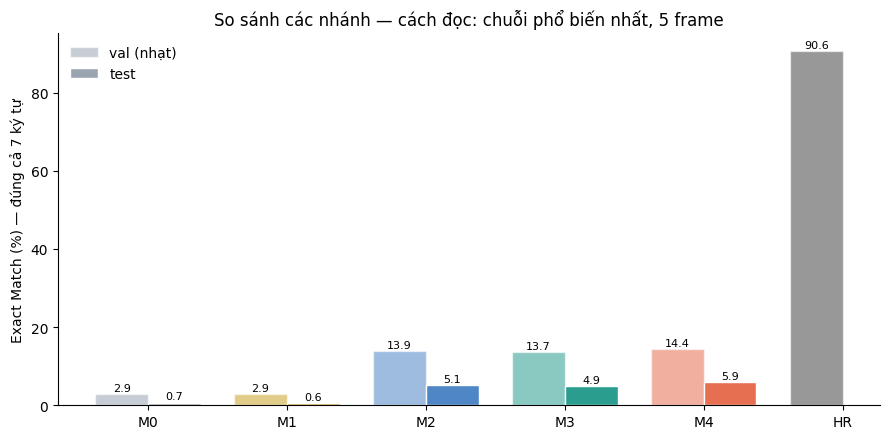

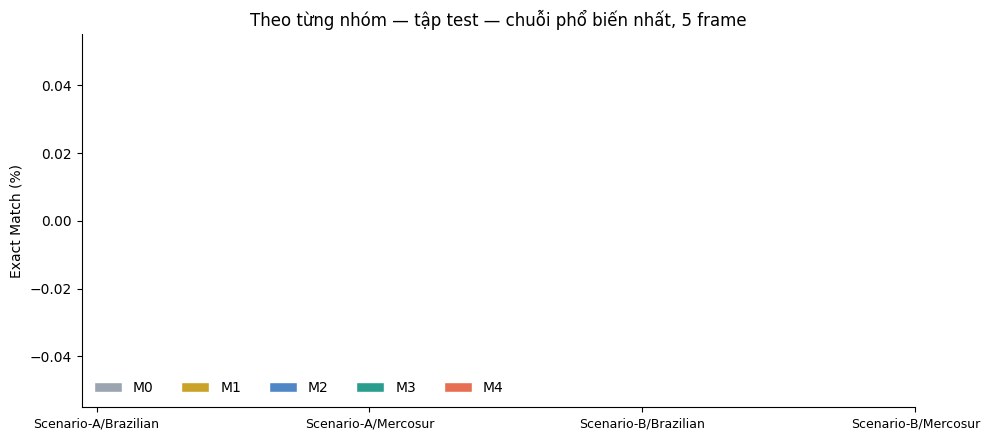

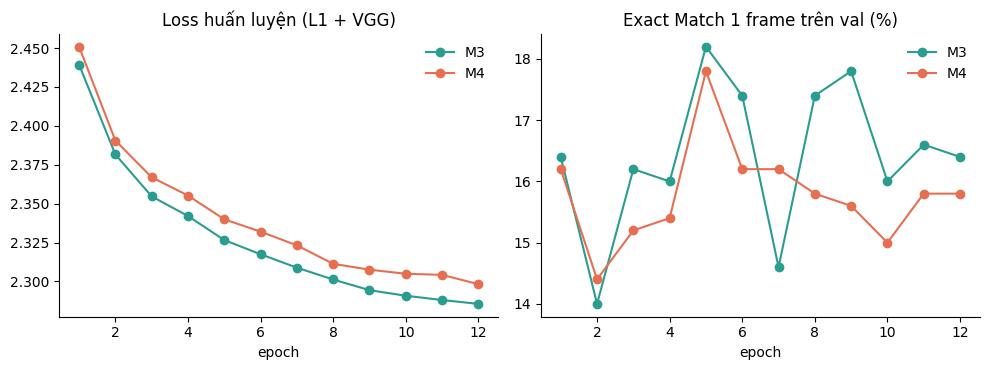

In [ ]:
import report_lib as R, eval_lib as E
with C.StepTimer('05 · Tổng hợp kết quả & bằng chứng', EVID_DIR):
    summary = R.gather_summary(RESULTS_DIR, out_csv=f'{RESULTS_DIR}/summary.csv')
    chosen = C.read_json(f'{RESULTS_DIR}/chosen_on_val.json')
    fusion = chosen['cach_gop_tot_nhat']
    best = chosen['mo_hinh_tot_nhat']
    ms = C.read_json(f'{RESULTS_DIR}/speed_ms_per_image.json') if os.path.exists(f'{RESULTS_DIR}/speed_ms_per_image.json') else {}
    R.write_comparison_md(f'{RESULTS_DIR}/comparison.md', summary, chosen, f'{EVID_DIR}/timing.csv', ms)
    R.plot_overview(summary, fusion, f'{RESULTS_DIR}/so_sanh_tong_quan.png')
    R.plot_groups(summary, fusion, 'test', f'{RESULTS_DIR}/so_sanh_theo_nhom_test.png')
    R.plot_training({'M3': f'{CKPT_DIR}/lpsrgan_M3/train_log.csv', 'M4': f'{CKPT_DIR}/lpsrgan_M4/train_log.csv'},
                    f'{RESULTS_DIR}/duong_cong_huan_luyen.png')
    R.confusion_pairs(RESULTS_DIR, fusion, f'{RESULTS_DIR}/confusion_pairs.csv')
    store = R.ResultStore(RESULTS_DIR)
    made = R.make_examples(store, 'test', fusion, best, f'{RESULTS_DIR}/examples')
    R.write_evidence_readme(f'{EVID_DIR}/README.md')
print(open(f'{RESULTS_DIR}/comparison.md', encoding='utf-8').read())

### Biểu đồ tổng quan

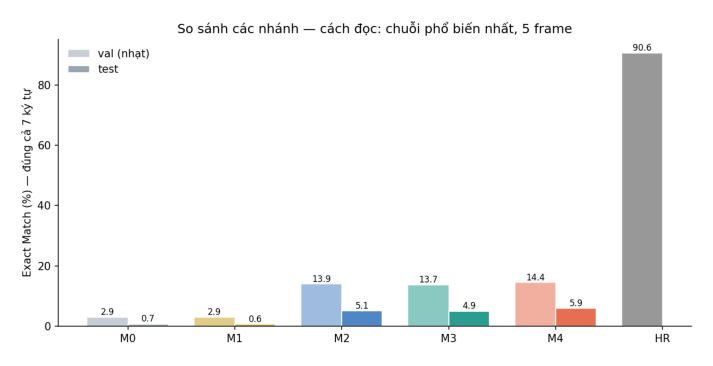

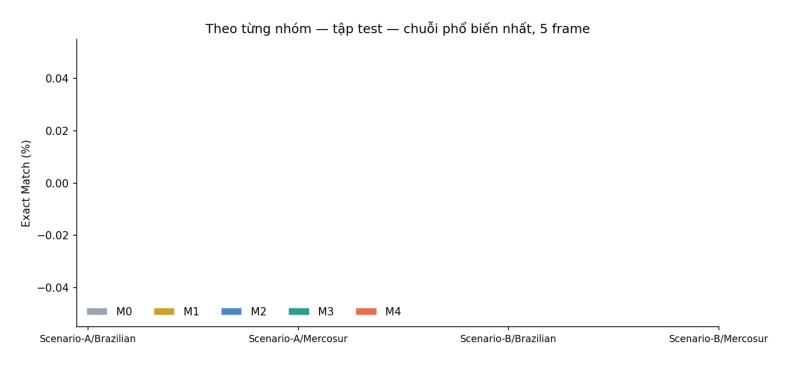

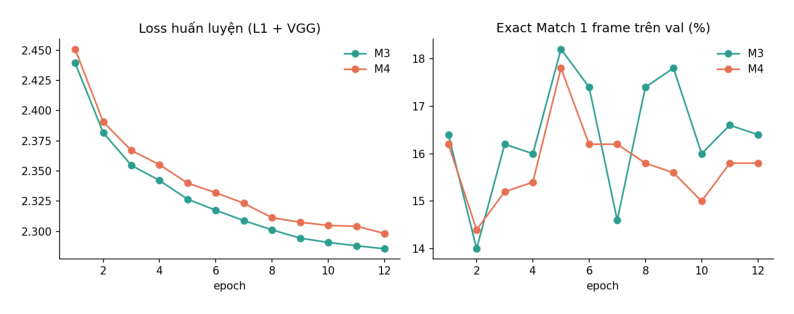

In [ ]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
for p in ('so_sanh_tong_quan.png', 'so_sanh_theo_nhom_test.png', 'duong_cong_huan_luyen.png'):
    if os.path.exists(f'{RESULTS_DIR}/{p}'):
        plt.figure(figsize=(10, 4.5)); plt.imshow(mpimg.imread(f'{RESULTS_DIR}/{p}')); plt.axis('off'); plt.show()

### Tra một ví dụ bất kỳ (để trả lời khi thầy hỏi)
Đổi `TRACK` thành mã track muốn xem (cột `track` trong `pred_test.csv`, ví dụ `test/track_10081`), hoặc để trống để xem các ca đã dựng sẵn.
Ô này chỉ **đọc lại từ file đã lưu**, không cần GPU.

— gan_dung_cv_sai : ['test/track_22174']


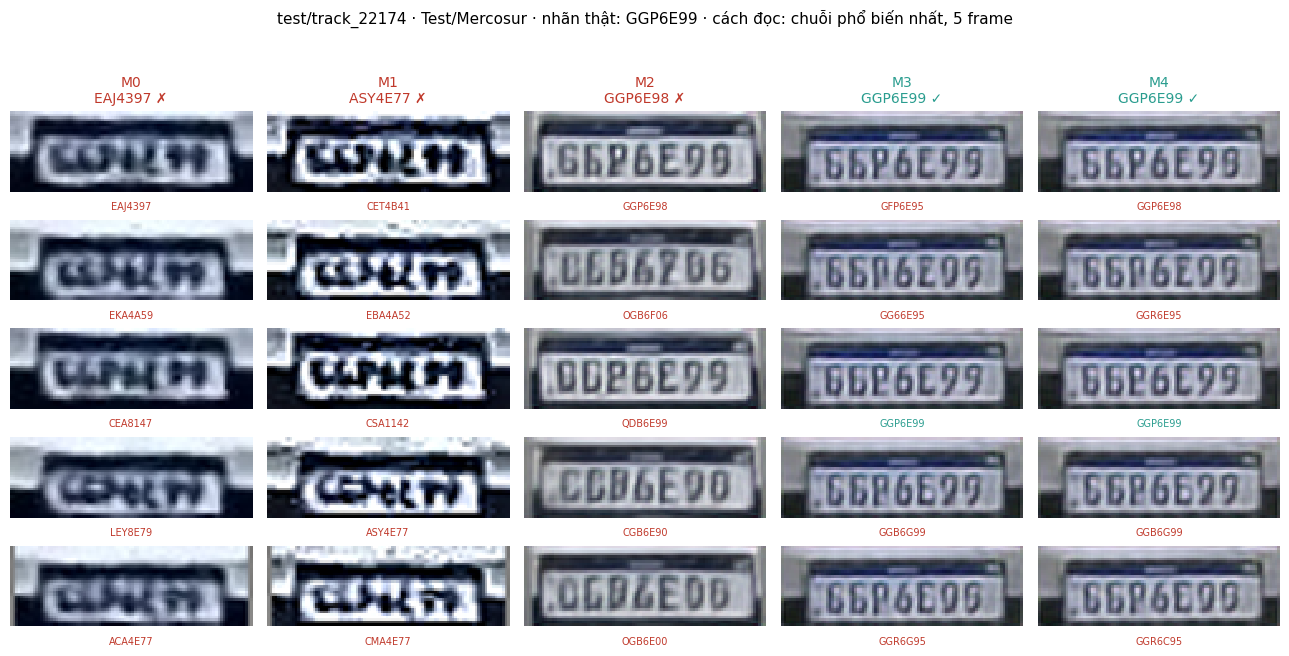

— ao_giac : ['test/track_12520']


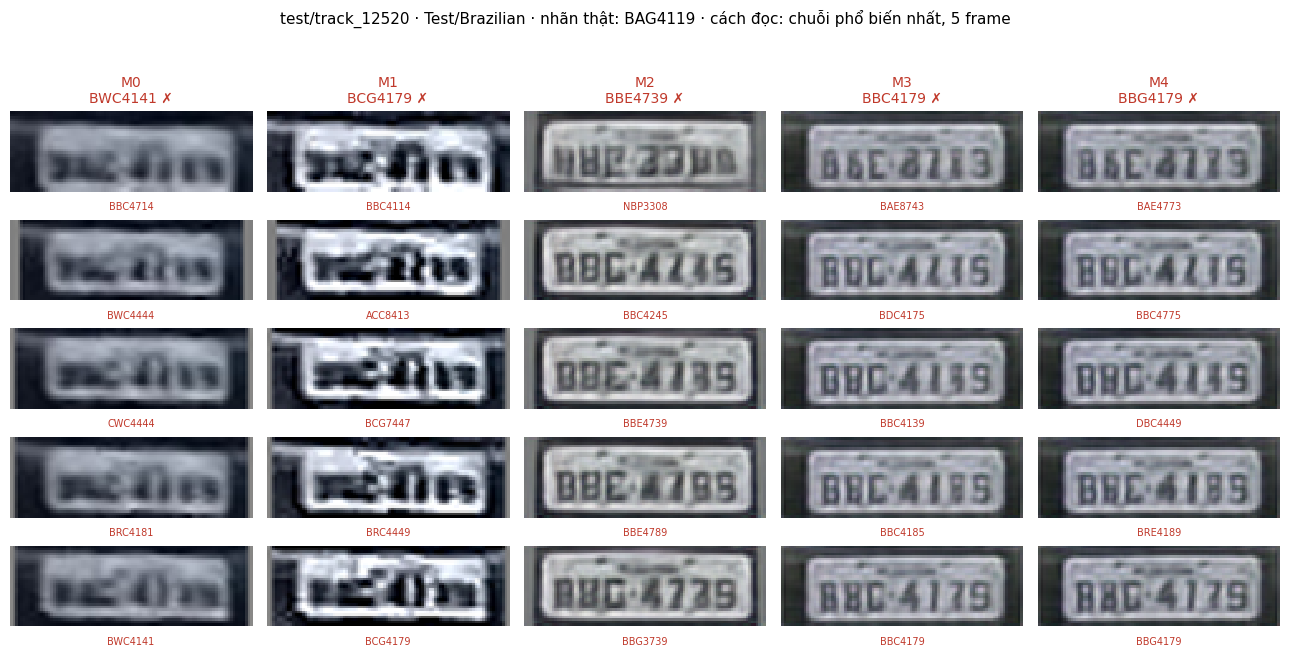

— dem : []
— ngay : []
— brazilian : ['test/track_10036']


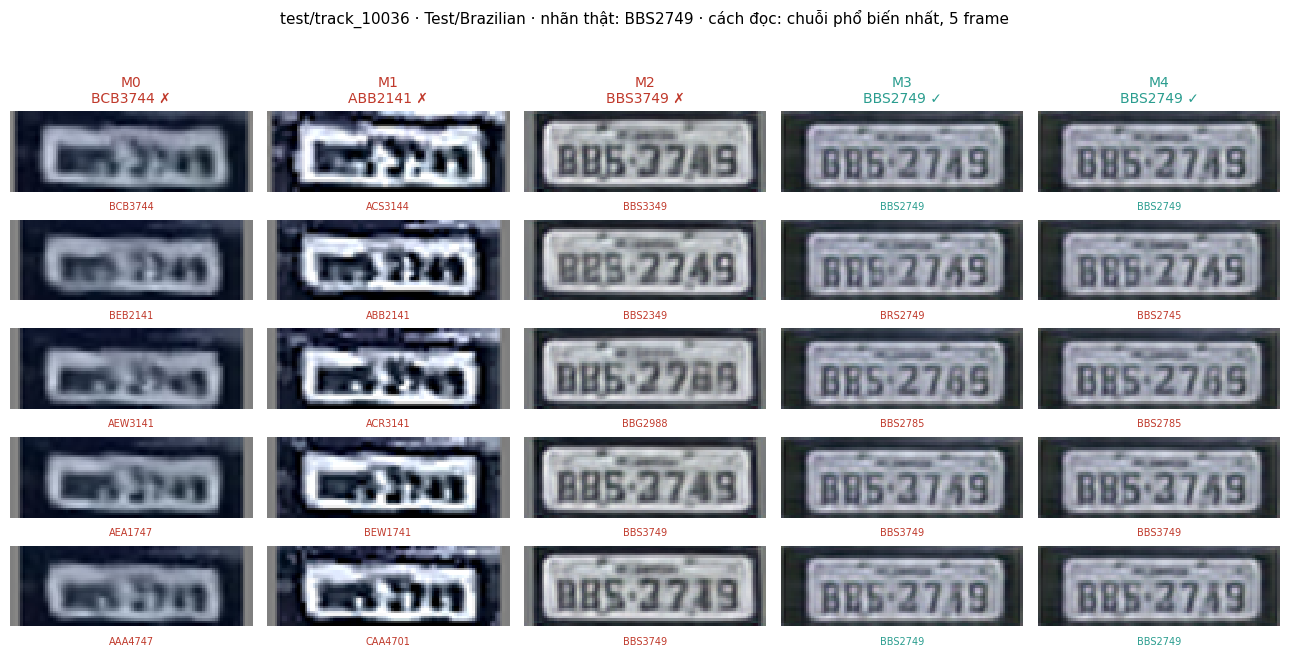

— mercosur : ['test/track_16986']


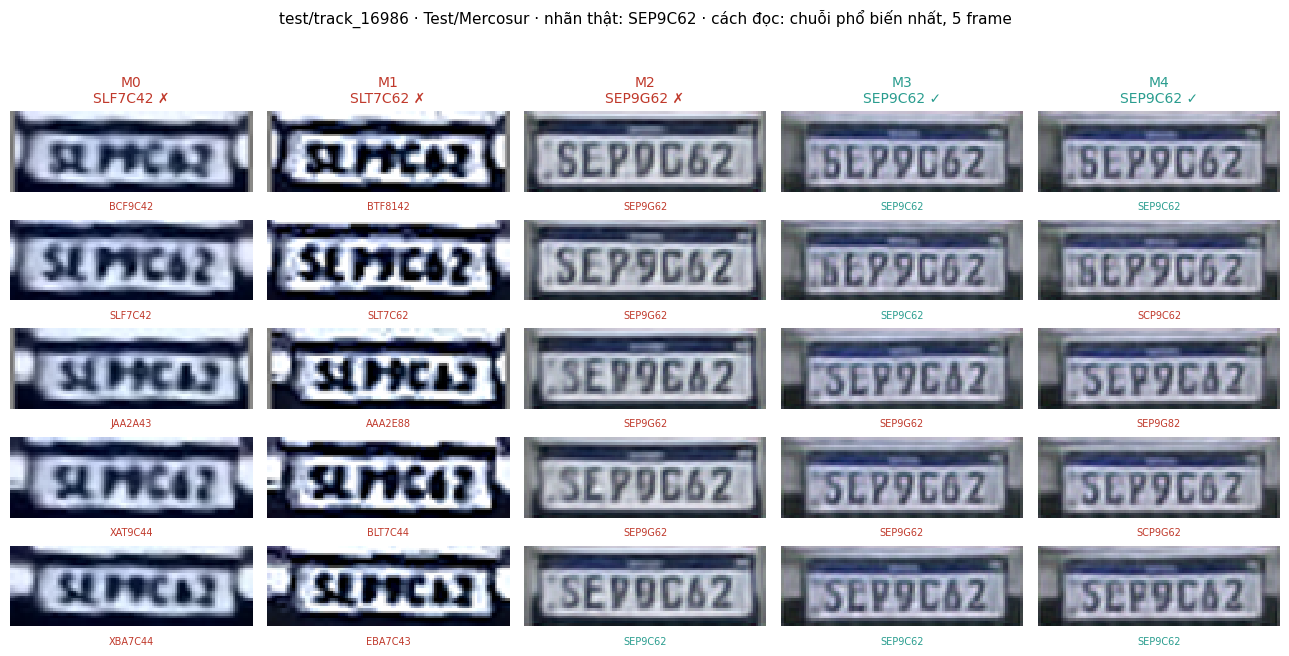

— sai_het : ['test/track_14881']


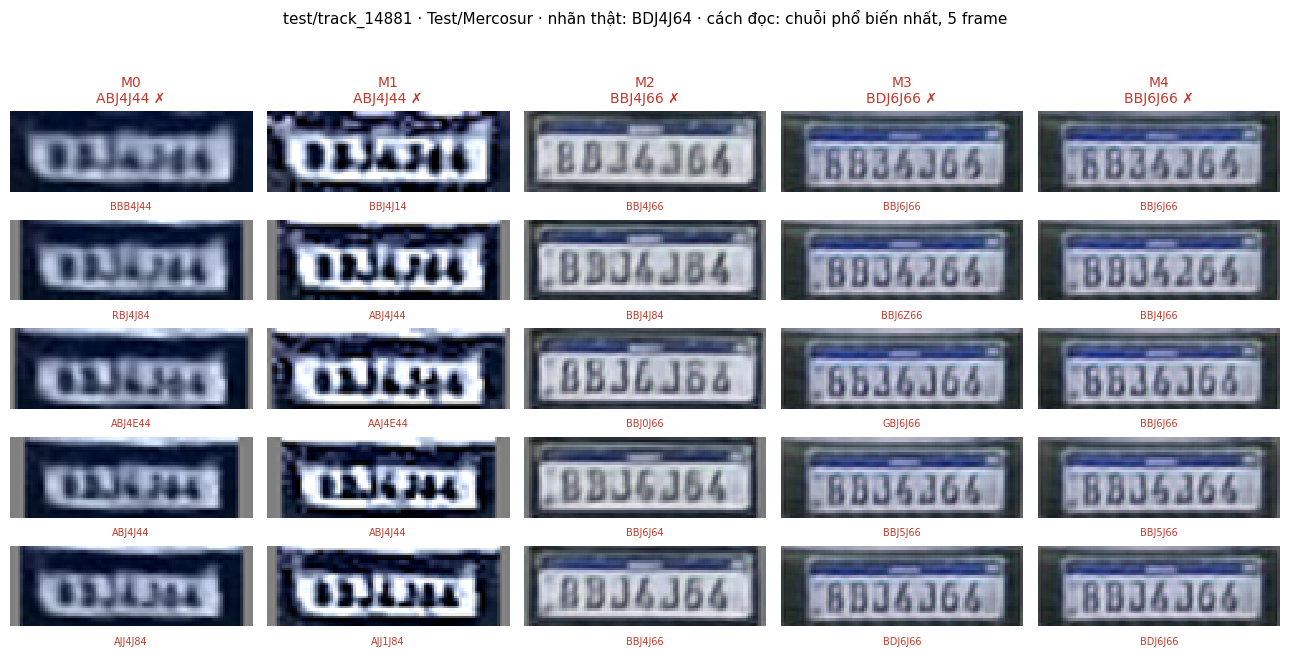

In [ ]:
TRACK = ''           # ví dụ: 'test/track_10081'. Để trống = xem các ca tiêu biểu
SPLIT_SHOW = 'test'  # 'test' hoặc 'val'
store = R.ResultStore(RESULTS_DIR)
chosen = C.read_json(f'{RESULTS_DIR}/chosen_on_val.json')
fusion, best = chosen['cach_gop_tot_nhat'], chosen['mo_hinh_tot_nhat']
if TRACK:
    R.show_track(store, TRACK, SPLIT_SHOW, fusion)
else:
    for cat, tracks in R.pick_examples(store, SPLIT_SHOW, fusion, best).items():
        print('—', cat, ':', tracks)
        for t in tracks:
            R.show_track(store, t, SPLIT_SHOW, fusion)

### Đóng gói bằng chứng
Tạo `MANIFEST.json` (sha256 mọi file) và file zip nhỏ (không gồm ảnh .npz và checkpoint) để gửi thầy.

In [ ]:
import zipfile
n = R.write_manifest({'results': RESULTS_DIR, 'evidence': EVID_DIR, 'splits': SPLIT_DIR, 'ckpt': CKPT_DIR},
                     f'{EVID_DIR}/MANIFEST.json')
print('MANIFEST.json:', n, 'file')
bundle = f'{DRIVE_DIR}/ket_qua_gui_thay.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as z:
    for name, root in {'results': RESULTS_DIR, 'evidence': EVID_DIR, 'splits': SPLIT_DIR, 'ckpt': CKPT_DIR}.items():
        for dp, _, fns in os.walk(root):
            for fn in fns:
                if fn.endswith(('.npz', '.pth', '.tmp')):
                    continue
                p = os.path.join(dp, fn)
                z.write(p, os.path.join(name, os.path.relpath(p, root)))
print(f'Đã tạo {bundle} ({os.path.getsize(bundle) / 1e6:.1f} MB)')
print('NHỚ: File → Tải xuống → .ipynb (kèm output) và đặt vào evidence/notebooks/')

MANIFEST.json: 73 file
Đã tạo /content/drive/MyDrive/MyCV/ket_qua_gui_thay.zip (3.6 MB)
NHỚ: File → Tải xuống → .ipynb (kèm output) và đặt vào evidence/notebooks/
